# Privacy Patent Trends by Category and CPC Code (>100 Patents)

| Item | Description |
|---|---|
| **Goal** | Dedicated yearly line graphs (1999–2021) for every privacy innovation category with **more than 100 patents ever granted**, ordered strictly from largest to smallest by total patent count, with the title of each CPC class and its official definition at the top of each graph. |
| **Input Data** | 1. `privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv` (72 CPC codes classified into 4 Claude clusters).<br>2. `patents/sample_firm_privacy_patents.csv` (sample firms' privacy patents with filing dates and matched CPC codes). |
| **Filter** | All categories with **$\ge 100$ patents** (55 individual CPC codes qualify, plus all 4 broad cluster groups). |
| **Ordering** | Ranked strictly from the largest total patent count to the smallest over 1999–2021. |
| **Color Coding** | Each category's graph is color-coded by its Claude cluster group:<br>• **Dodger Blue (`#1976D2`)**: Group A — Privacy Protection (PII, Anonymity, PETs)<br>• **Deep Orange (`#E65100`)**: Group B — Use of Personal Data (Tracking, Profiling, Targeting)<br>• **Deep Purple (`#5E35B1`)**: Group C — Interception by Authorities<br>• **Forest Green (`#2E7D32`)**: Group D — Security (Encryption, Access Control, Obfuscation) |
| **Exports** | All figures saved to `output/X1.2.7/` in **PNG (300 DPI)**, **PDF**, and **SVG** vector formats, along with ranked summary and time-series CSVs. |


## Step 1. Import packages


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import textwrap


## Step 2. Define file locations, styling, and cluster color palette


In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_FOLDER = NOTEBOOK_DIR if (NOTEBOOK_DIR / "X1 - Example of Research Enabled by LLM Pipeline").exists() else NOTEBOOK_DIR.parents[1]
SECTION_FOLDER = PROJECT_FOLDER / "X1 - Example of Research Enabled by LLM Pipeline"

PATENTS_CSV = SECTION_FOLDER / "patents/sample_firm_privacy_patents.csv"
CLUSTERED_CSV = SECTION_FOLDER / "privacy_cpc/privacy_cpc_codes_clustered_by_claude.csv"
OUTPUT_DIR = SECTION_FOLDER / "output/X1.2.7"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# S3 styling
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "serif"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8

# Color coding by Claude cluster group
GROUP_COLORS = {
    "A. Privacy protection (PII, anonymity, privacy-enhancing cryptography)": "#1976D2",
    "B. Use of personal data (tracking, profiling, targeting, monitoring people)": "#E65100",
    "C. Interception by authorities": "#5E35B1",
    "D. Security (encryption, access control, secure storage, obfuscation)": "#2E7D32",
}

GROUP_SHORT_NAMES = {
    "A. Privacy protection (PII, anonymity, privacy-enhancing cryptography)": "Privacy Protection",
    "B. Use of personal data (tracking, profiling, targeting, monitoring people)": "Use of Personal Data",
    "C. Interception by authorities": "Interception by Authorities",
    "D. Security (encryption, access control, secure storage, obfuscation)": "Security",
}

YEARS = list(range(1999, 2022))
print("Setup complete. Output path:", OUTPUT_DIR)


Setup complete. Output path: ...


## Step 3. Load privacy patents dataset and Claude clustered definitions


In [3]:
df_patents = pd.read_csv(PATENTS_CSV)
df_patents["filing_date"] = pd.to_datetime(df_patents["filing_date"])
df_patents["filing_year"] = df_patents["filing_date"].dt.year

df_clustered = pd.read_csv(CLUSTERED_CSV)
df_clustered["cpc_clean"] = df_clustered["cpc_display"].str.replace(" ", "", regex=False)

# Categories with >= 100 patents
df_gt100 = df_clustered[df_clustered["n_privacy_patents"] >= 100].sort_values("n_privacy_patents", ascending=False).reset_index(drop=True)
df_gt100["rank"] = df_gt100.index + 1

print(f"Total patent-code rows in dataset: {len(df_patents):,}")
print(f"Unique sample-firm patents: {df_patents['patent_num'].nunique():,}")
print(f"Categories in cluster list: {len(df_clustered)} | Categories with >= 100 patents: {len(df_gt100)}")


Total patent-code rows in dataset: 47,225
Unique sample-firm patents: 33,986
Categories in cluster list: 72 | Categories with >= 100 patents: 55


## Step 4. Summary Table of All 55 Categories Ranked Largest to Smallest


In [4]:
df_display_table = df_gt100[["rank", "cpc_display", "group", "n_privacy_patents", "definition"]].copy()
df_display_table.rename(columns={
    "rank": "Rank",
    "cpc_display": "CPC Code",
    "group": "Claude Group",
    "n_privacy_patents": "Total Patents",
    "definition": "Official Definition"
}, inplace=True)

df_display_table


Rank,CPC Code,Group,Total Patents,Peak Year,Peak Count,Definition
1,H04L 63/0428,"Security (Encryption, Access Control, Obfuscation)",4394,2017,435,"wherein the data content is protected, e.g. by encrypting or encapsulating the payload"
2,H04L 63/10,"Security (Encryption, Access Control, Obfuscation)",4135,2017,419,for controlling access to devices or network resources
3,G06F 21/6218,"Security (Encryption, Access Control, Obfuscation)",4057,2017,359,"to a system of files or objects, e.g. local or distributed file system or database"
4,H04W 12/08,"Security (Encryption, Access Control, Obfuscation)",3086,2015,328,Access security
5,H04W 4/029,"Use of Personal Data (Tracking, Profiling, Targeting)",2577,2019,410,Location-based management or tracking services
6,G06F 21/602,"Security (Encryption, Access Control, Obfuscation)",2349,2019,342,Providing cryptographic facilities or services
7,G06F 21/6245,"Privacy Protection (PII, Anonymity)",2124,2019,257,"Protecting personal data, e.g. for financial or medical purposes"
8,H04W 12/02,"Privacy Protection (PII, Anonymity)",1519,2016,147,"Protecting privacy or anonymity, e.g. protecting personally identifiable information [PII]"
9,G06Q 30/0269,"Use of Personal Data (Tracking, Profiling, Targeting)",1430,2014,172,based on user profile or attribute
10,G06F 21/62,"Security (Encryption, Access Control, Obfuscation)",1318,2017,131,"Protecting access to data via a platform, e.g. using keys or access control rules"


---
# Part A. The 4 Broad Claude Groups (Ranked Largest to Smallest)

Distinct sample-firm patents carrying at least one CPC code belonging to each Claude cluster group over 1999 to 2021.


### Group D. Security (Encryption, Access Control, Obfuscation) (23,266 Unique Patents)


Group D (23,266 unique patents): Peak in 2017 (2,041 patents)


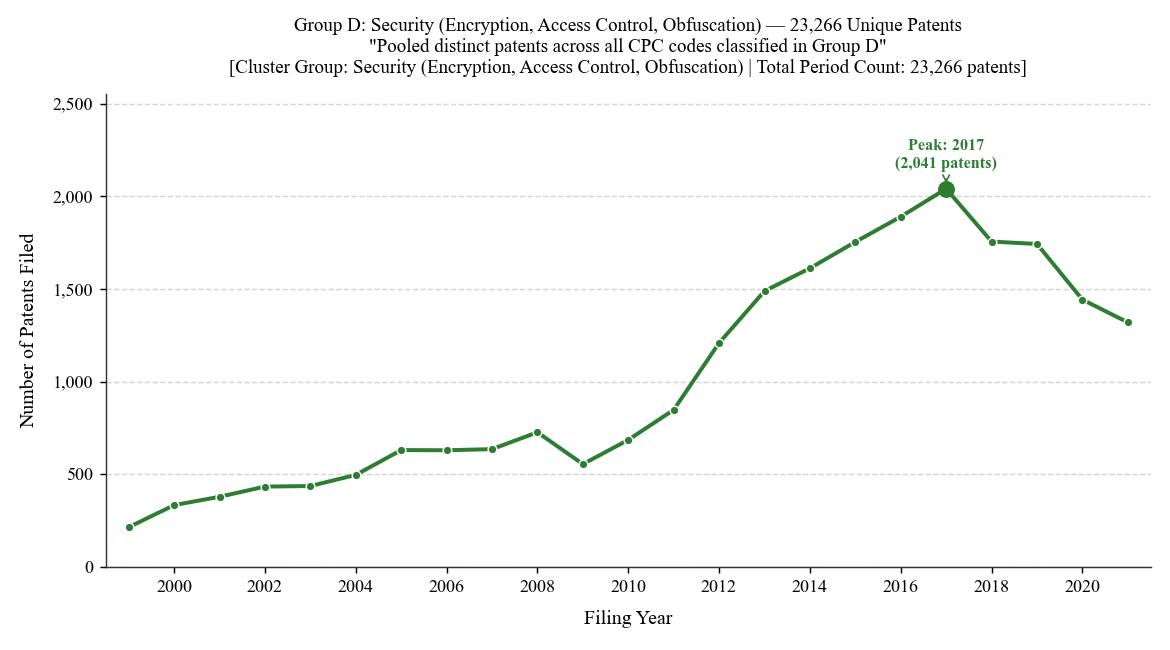

In [11]:
# Group D: Security (Encryption, Access Control, Obfuscation)
# Output files: fig_group_D_security_encryption_access_control_obfuscation.png, fig_group_D_security_encryption_access_control_obfuscation.pdf, fig_group_D_security_encryption_access_control_obfuscation.svg


### Group B. Use of Personal Data (Tracking, Profiling, Targeting) (7,293 Unique Patents)


Group B (7,293 unique patents): Peak in 2020 (847 patents)


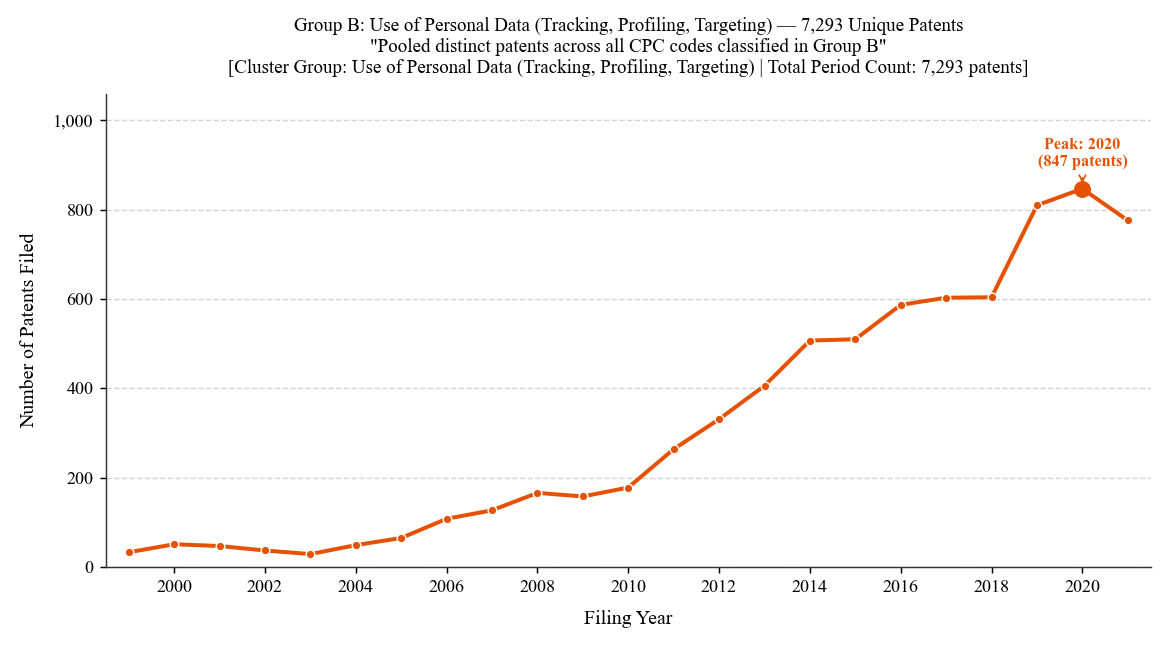

In [13]:
# Group B: Use of Personal Data (Tracking, Profiling, Targeting)
# Output files: fig_group_B_use_of_personal_data_tracking_profiling_targeting.png, fig_group_B_use_of_personal_data_tracking_profiling_targeting.pdf, fig_group_B_use_of_personal_data_tracking_profiling_targeting.svg


### Group A. Privacy Protection (PII, Anonymity) (6,467 Unique Patents)


Group A (6,467 unique patents): Peak in 2019 (697 patents)


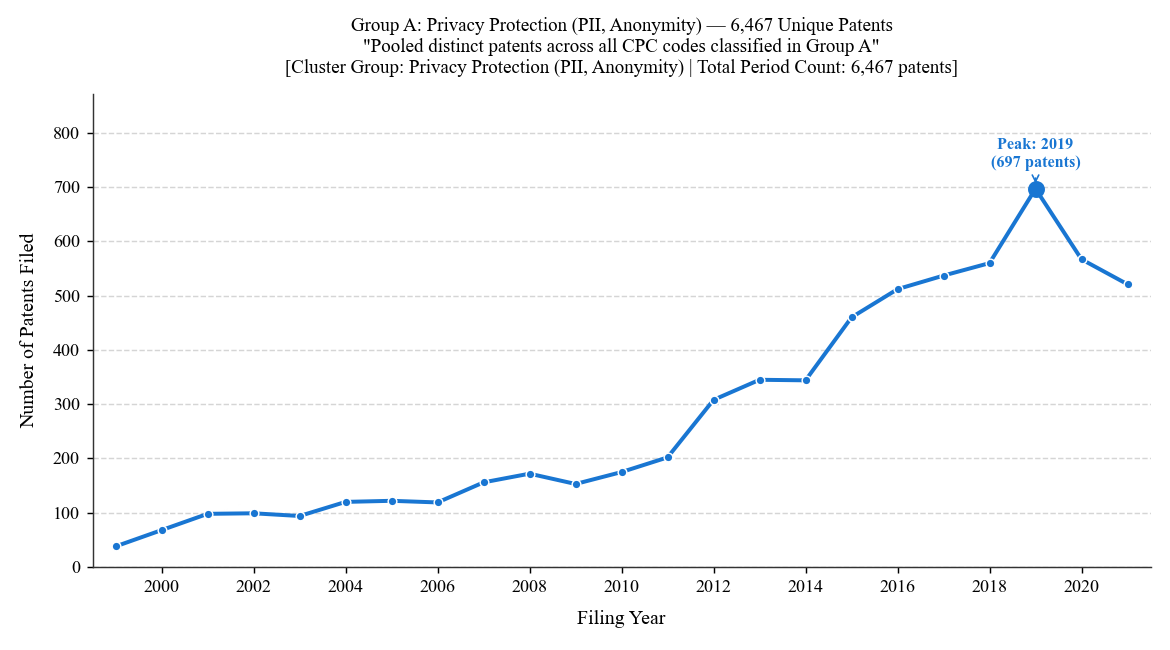

In [15]:
# Group A: Privacy Protection (PII, Anonymity)
# Output files: fig_group_A_privacy_protection_pii_anonymity.png, fig_group_A_privacy_protection_pii_anonymity.pdf, fig_group_A_privacy_protection_pii_anonymity.svg


### Group C. Interception by Authorities (182 Unique Patents)


Group C (182 unique patents): Peak in 2010 (16 patents)


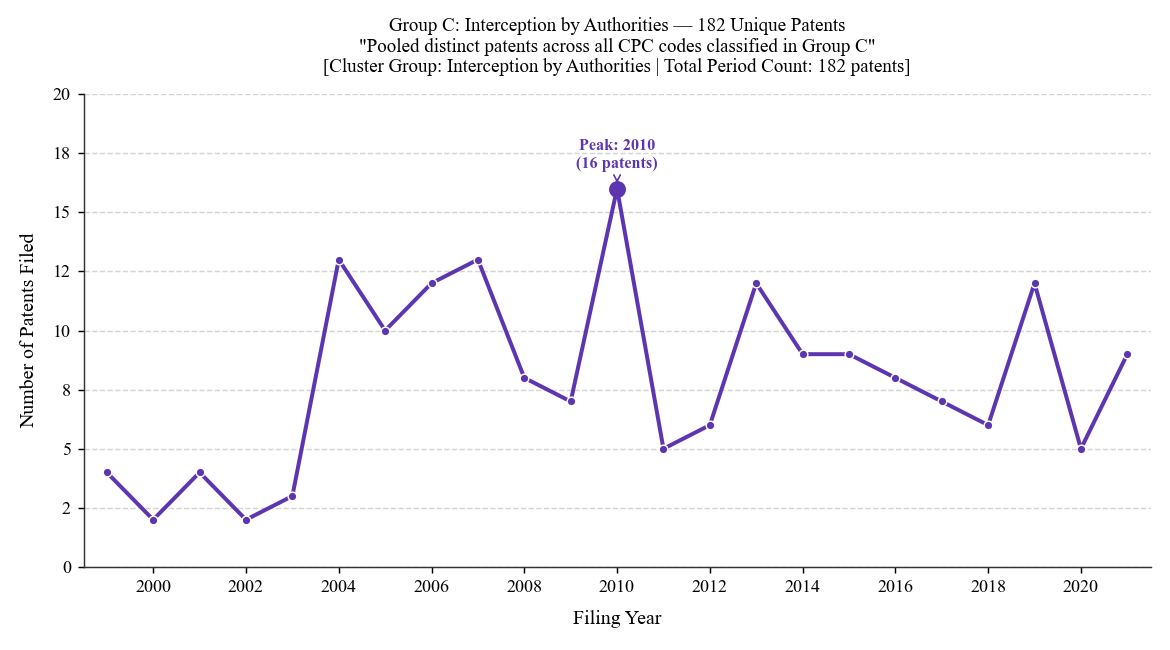

In [17]:
# Group C: Interception by Authorities
# Output files: fig_group_C_interception_by_authorities.png, fig_group_C_interception_by_authorities.pdf, fig_group_C_interception_by_authorities.svg


---
# Part B. All 55 Categories with > 100 Patents (Ranked 1 to 55 from Largest to Smallest)

Individual yearly line graphs from 1999 to 2021 for each category/CPC code with the official definition and group tag prominently displayed.


### Rank 1. H04L 63/0428: wherein the data content is protected, e.g. by encrypting or encapsulating the p... (4,394 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"wherein the data content is protected, e.g. by encrypting or encapsulating the payload"*


Rank 1: H04L 63/0428 | Total: 4,394 patents | Peak: 2017 (435 patents)


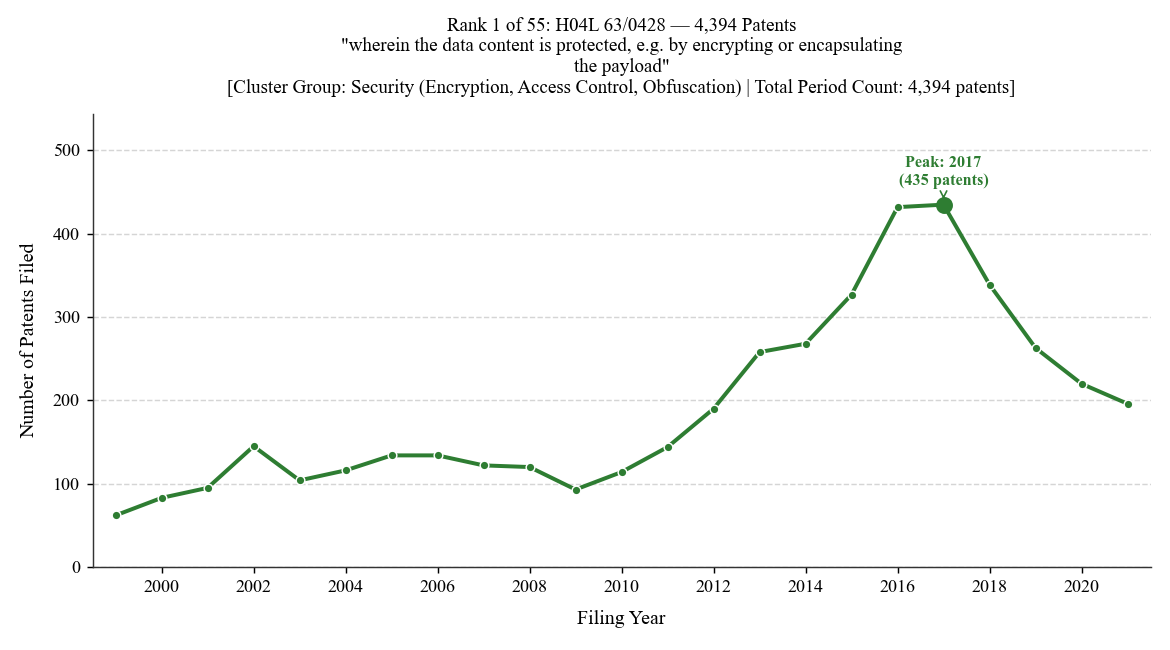

In [20]:
# Rank 1: H04L 63/0428 (4,394 patents)
# Peak: 2017 (435 patents) | Files: fig_rank_01_H04L63_0428.{png,pdf,svg}


### Rank 2. H04L 63/10: for controlling access to devices or network resources... (4,135 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"for controlling access to devices or network resources"*


Rank 2: H04L 63/10 | Total: 4,135 patents | Peak: 2017 (419 patents)


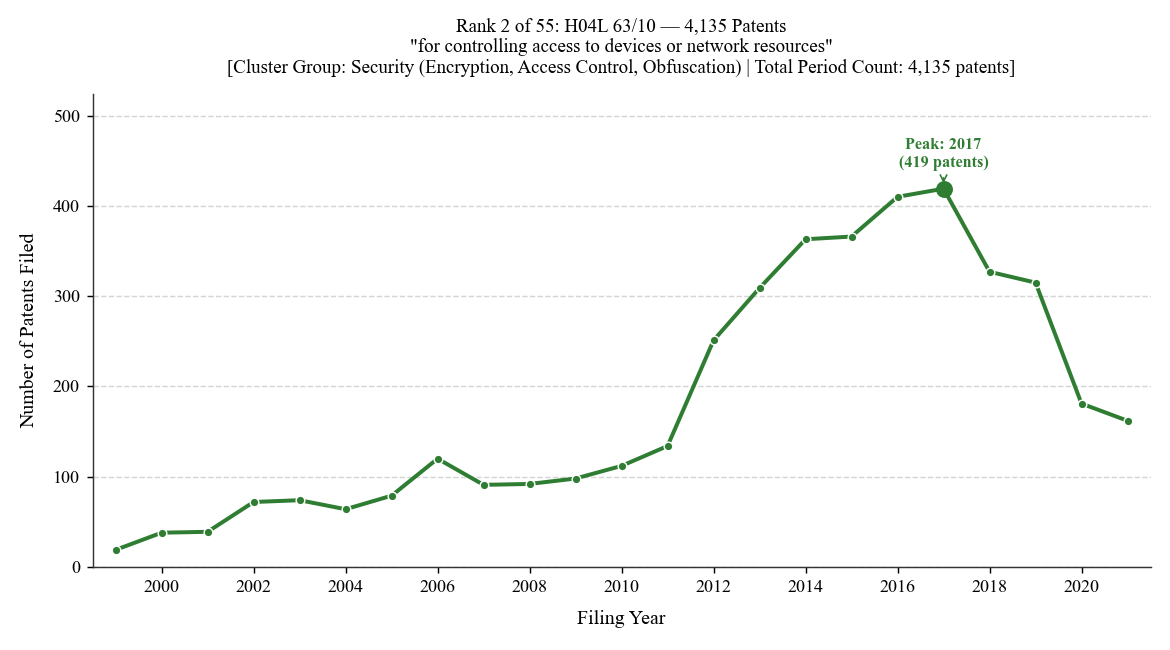

In [22]:
# Rank 2: H04L 63/10 (4,135 patents)
# Peak: 2017 (419 patents) | Files: fig_rank_02_H04L63_10.{png,pdf,svg}


### Rank 3. G06F 21/6218: to a system of files or objects, e.g. local or distributed file system or databa... (4,057 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"to a system of files or objects, e.g. local or distributed file system or database"*


Rank 3: G06F 21/6218 | Total: 4,057 patents | Peak: 2017 (359 patents)


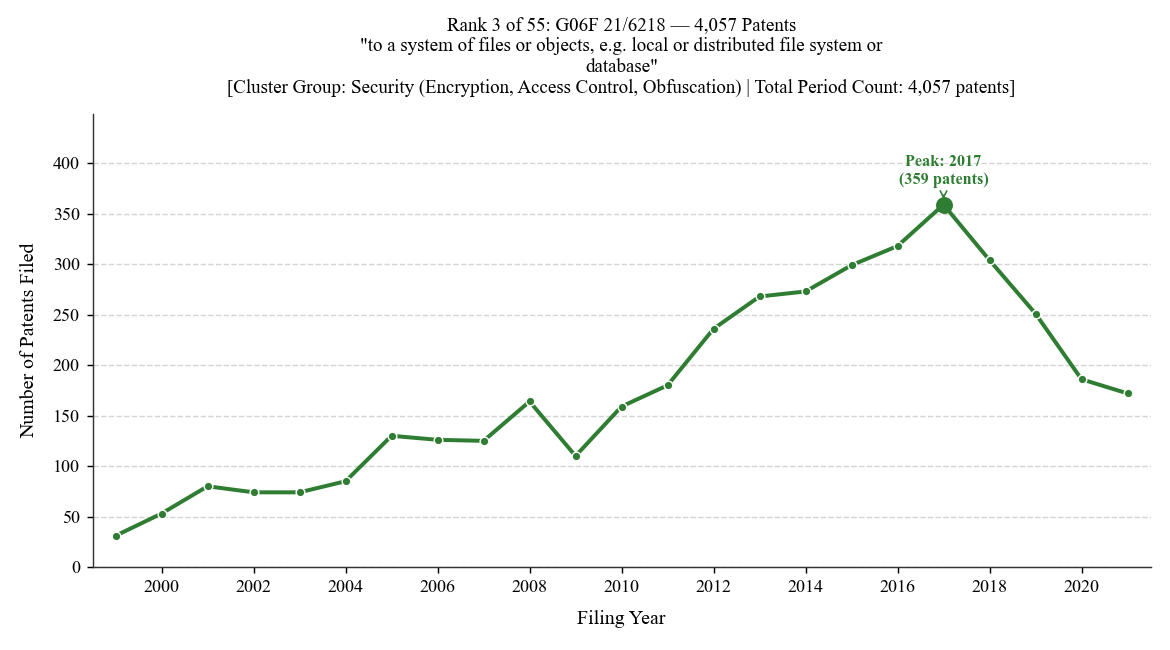

In [24]:
# Rank 3: G06F 21/6218 (4,057 patents)
# Peak: 2017 (359 patents) | Files: fig_rank_03_G06F21_6218.{png,pdf,svg}


### Rank 4. H04W 12/08: Access security... (3,086 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Access security"*


Rank 4: H04W 12/08 | Total: 3,086 patents | Peak: 2015 (328 patents)


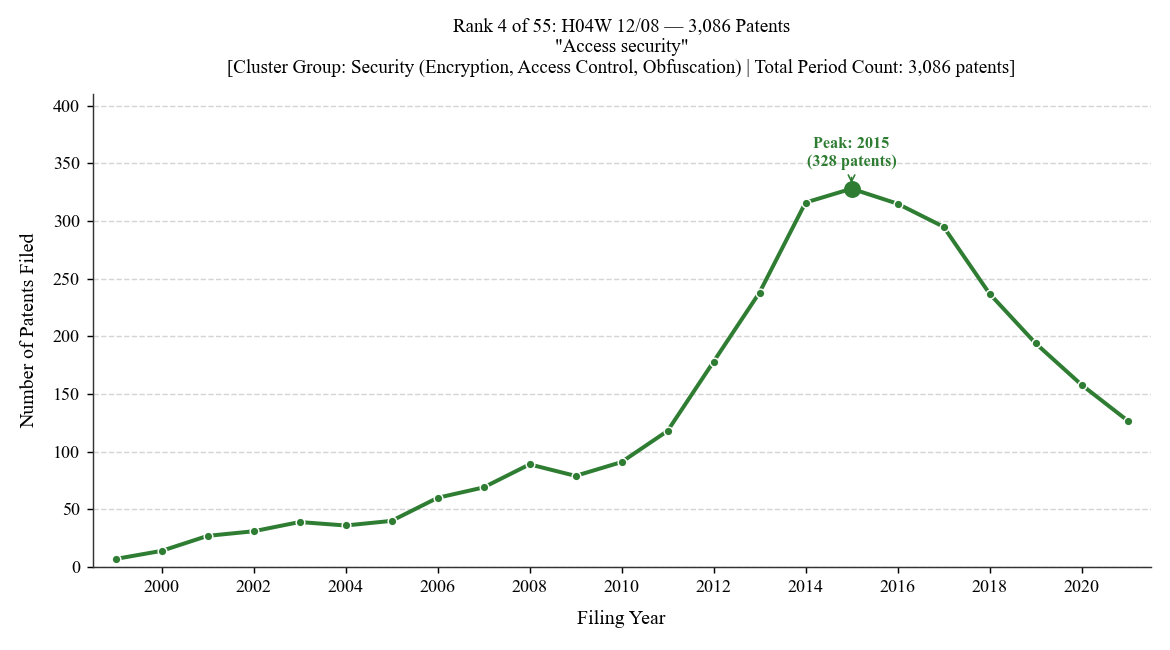

In [26]:
# Rank 4: H04W 12/08 (3,086 patents)
# Peak: 2015 (328 patents) | Files: fig_rank_04_H04W12_08.{png,pdf,svg}


### Rank 5. H04W 4/029: Location-based management or tracking services... (2,577 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"Location-based management or tracking services"*


Rank 5: H04W 4/029 | Total: 2,577 patents | Peak: 2019 (410 patents)


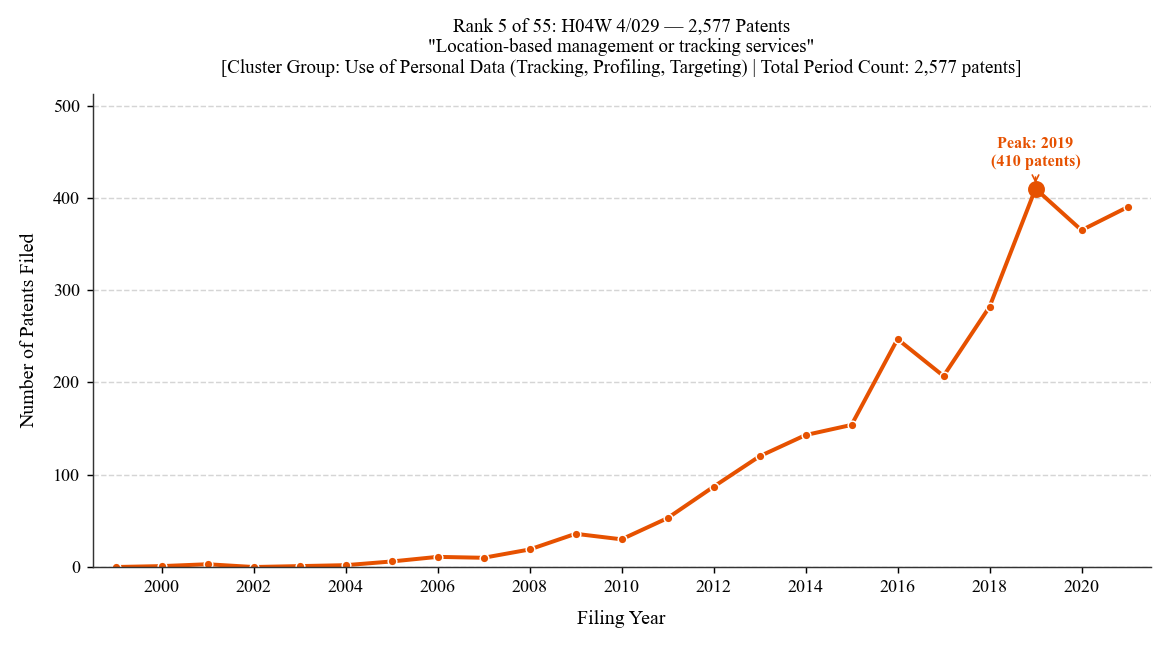

In [28]:
# Rank 5: H04W 4/029 (2,577 patents)
# Peak: 2019 (410 patents) | Files: fig_rank_05_H04W4_029.{png,pdf,svg}


### Rank 6. G06F 21/602: Providing cryptographic facilities or services... (2,349 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Providing cryptographic facilities or services"*


Rank 6: G06F 21/602 | Total: 2,349 patents | Peak: 2019 (342 patents)


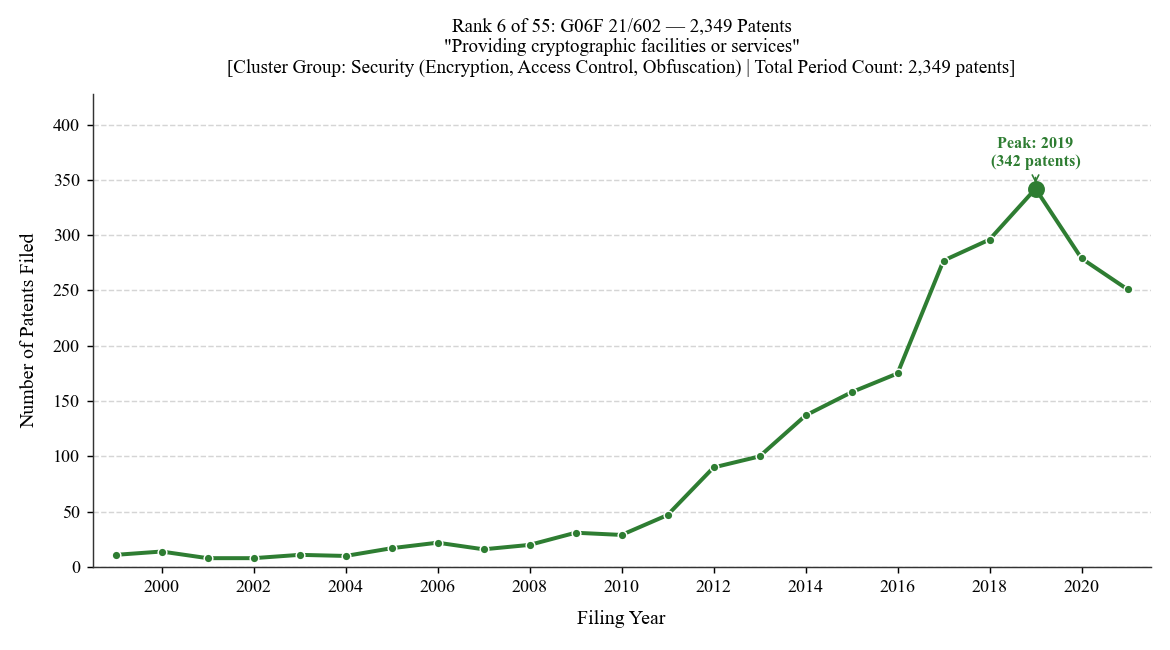

In [30]:
# Rank 6: G06F 21/602 (2,349 patents)
# Peak: 2019 (342 patents) | Files: fig_rank_06_G06F21_602.{png,pdf,svg}


### Rank 7. G06F 21/6245: Protecting personal data, e.g. for financial or medical purposes... (2,124 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"Protecting personal data, e.g. for financial or medical purposes"*


Rank 7: G06F 21/6245 | Total: 2,124 patents | Peak: 2019 (257 patents)


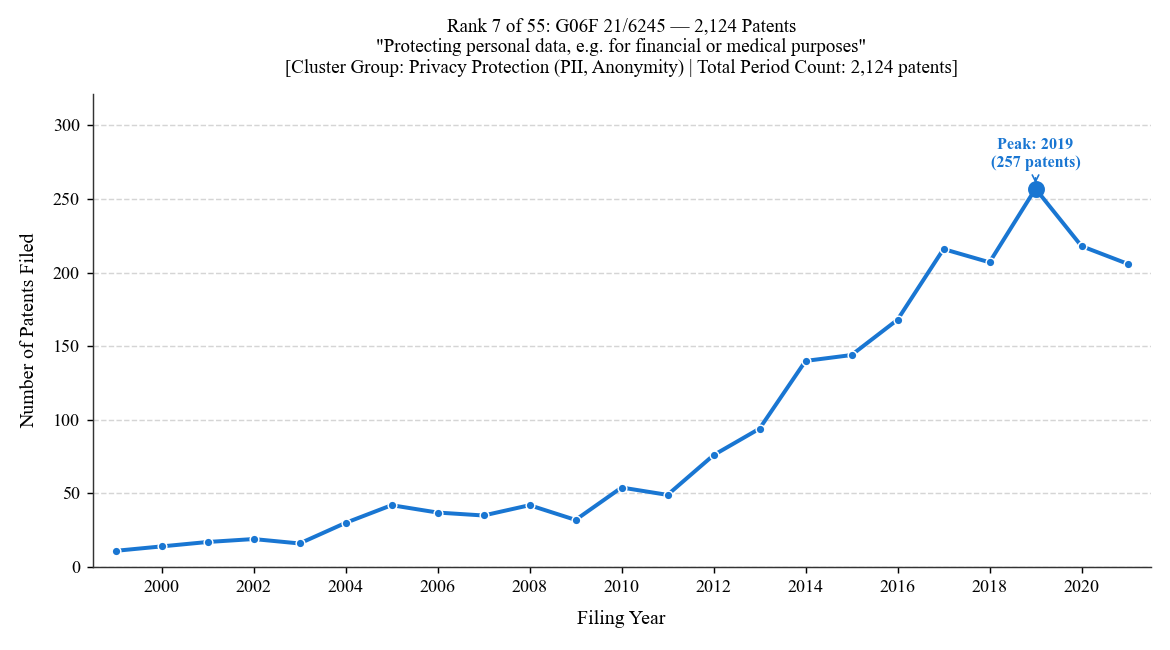

In [32]:
# Rank 7: G06F 21/6245 (2,124 patents)
# Peak: 2019 (257 patents) | Files: fig_rank_07_G06F21_6245.{png,pdf,svg}


### Rank 8. H04W 12/02: Protecting privacy or anonymity, e.g. protecting personally identifiable informa... (1,519 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"Protecting privacy or anonymity, e.g. protecting personally identifiable information [PII]"*


Rank 8: H04W 12/02 | Total: 1,519 patents | Peak: 2016 (147 patents)


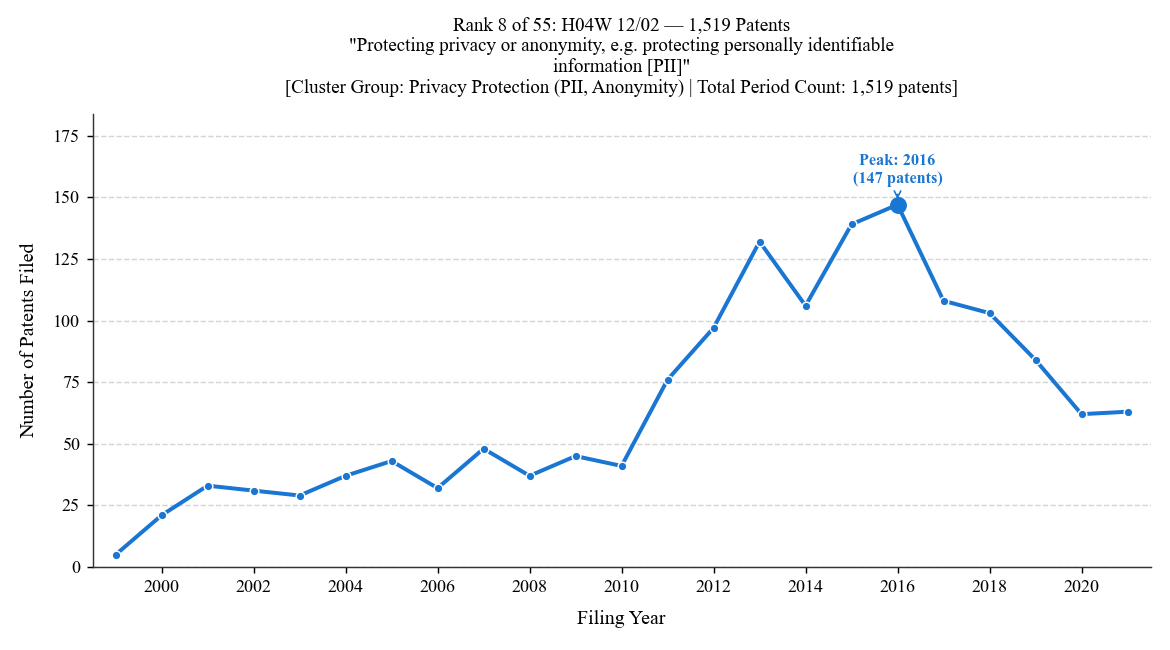

In [34]:
# Rank 8: H04W 12/02 (1,519 patents)
# Peak: 2016 (147 patents) | Files: fig_rank_08_H04W12_02.{png,pdf,svg}


### Rank 9. G06Q 30/0269: based on user profile or attribute... (1,430 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"based on user profile or attribute"*


Rank 9: G06Q 30/0269 | Total: 1,430 patents | Peak: 2014 (172 patents)


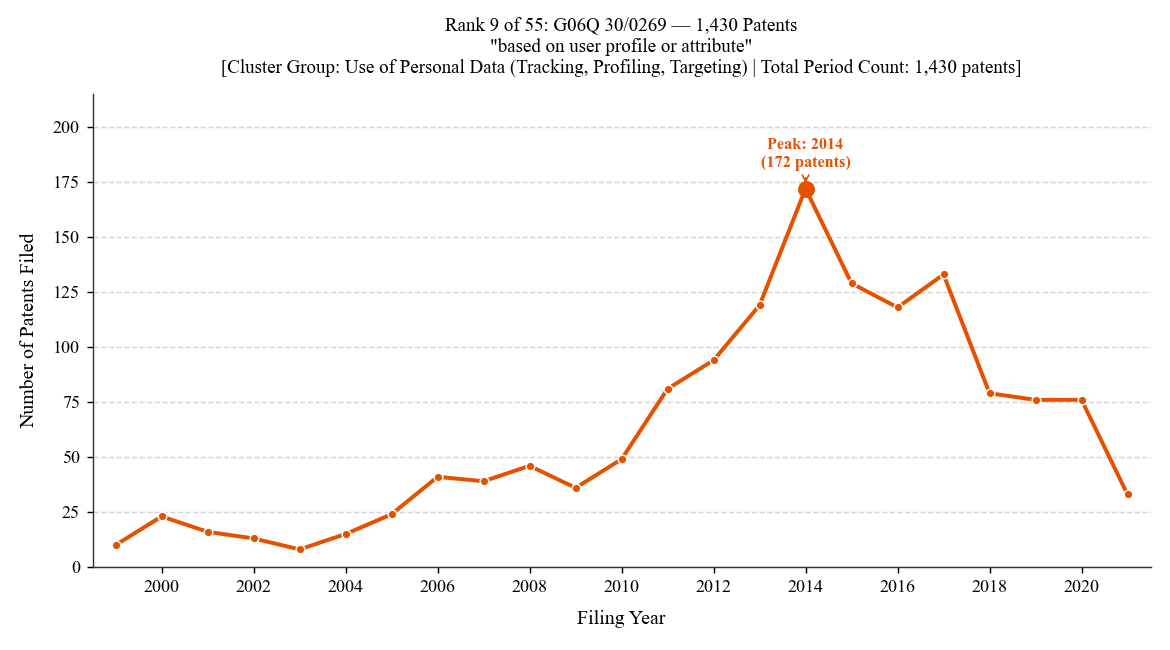

In [36]:
# Rank 9: G06Q 30/0269 (1,430 patents)
# Peak: 2014 (172 patents) | Files: fig_rank_09_G06Q30_0269.{png,pdf,svg}


### Rank 10. G06F 21/62: Protecting access to data via a platform, e.g. using keys or access control rule... (1,318 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Protecting access to data via a platform, e.g. using keys or access control rules"*


Rank 10: G06F 21/62 | Total: 1,318 patents | Peak: 2017 (131 patents)


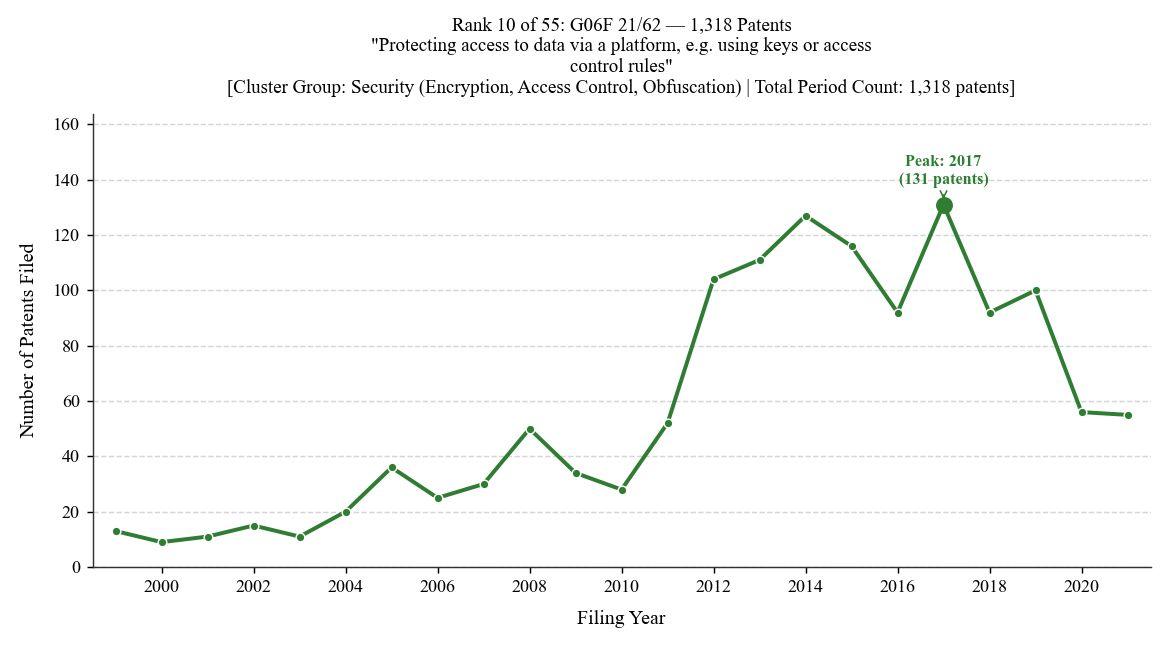

In [38]:
# Rank 10: G06F 21/62 (1,318 patents)
# Peak: 2017 (131 patents) | Files: fig_rank_10_G06F21_62.{png,pdf,svg}


### Rank 11. G06F 21/6227: where protection concerns the structure of data, e.g. records, types, queries... (1,244 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"where protection concerns the structure of data, e.g. records, types, queries"*


Rank 11: G06F 21/6227 | Total: 1,244 patents | Peak: 2019 (117 patents)


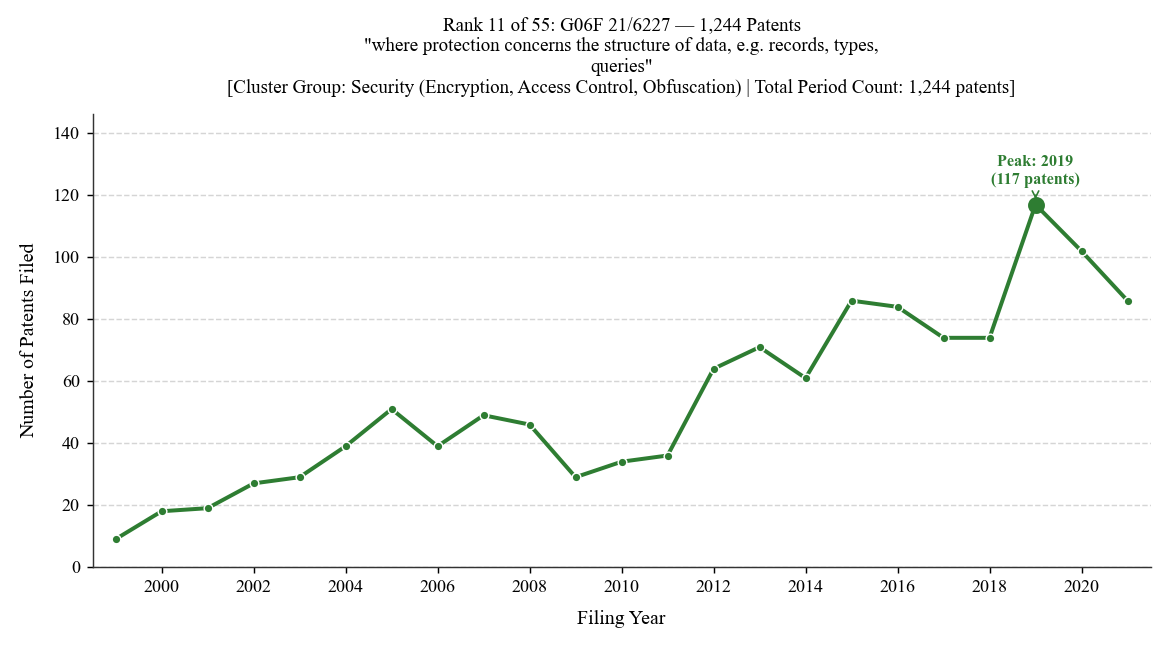

In [40]:
# Rank 11: G06F 21/6227 (1,244 patents)
# Peak: 2019 (117 patents) | Files: fig_rank_11_G06F21_6227.{png,pdf,svg}


### Rank 12. G06F 21/6209: to a single file or object, e.g. in a secure envelope, encrypted and accessed us... (1,224 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"to a single file or object, e.g. in a secure envelope, encrypted and accessed using a key, or with access control rules appended to the object itself"*


Rank 12: G06F 21/6209 | Total: 1,224 patents | Peak: 2015 (102 patents)


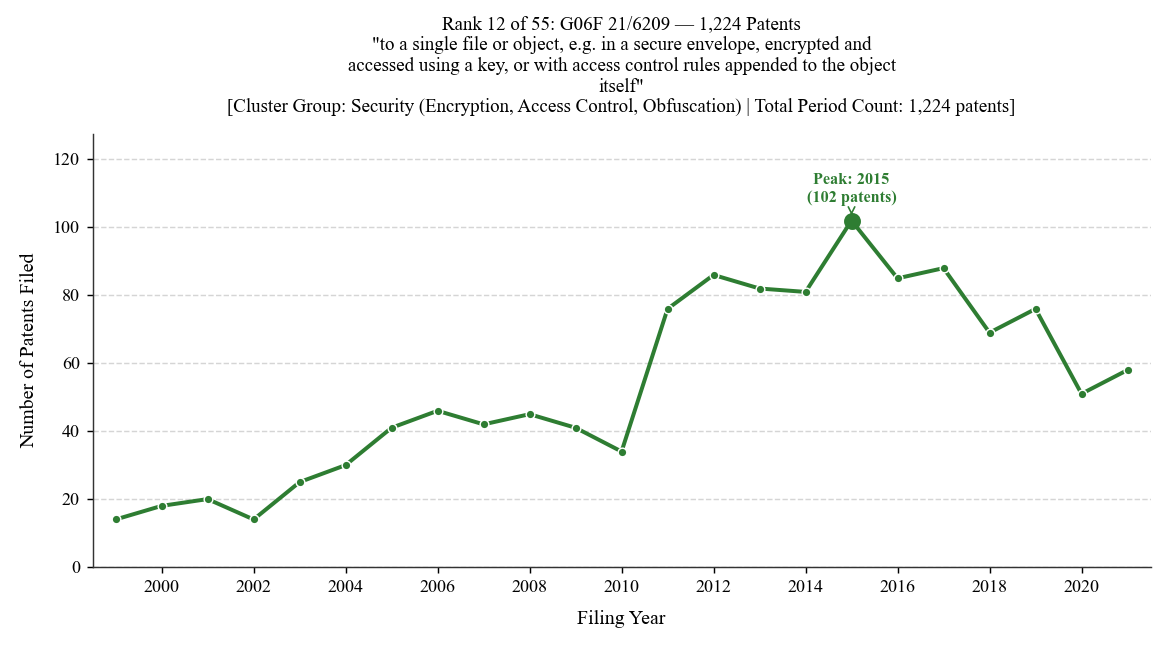

In [42]:
# Rank 12: G06F 21/6209 (1,224 patents)
# Peak: 2015 (102 patents) | Files: fig_rank_12_G06F21_6209.{png,pdf,svg}


### Rank 13. G06Q 30/0255: based on user history... (1,011 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"based on user history"*


Rank 13: G06Q 30/0255 | Total: 1,011 patents | Peak: 2015 (106 patents)


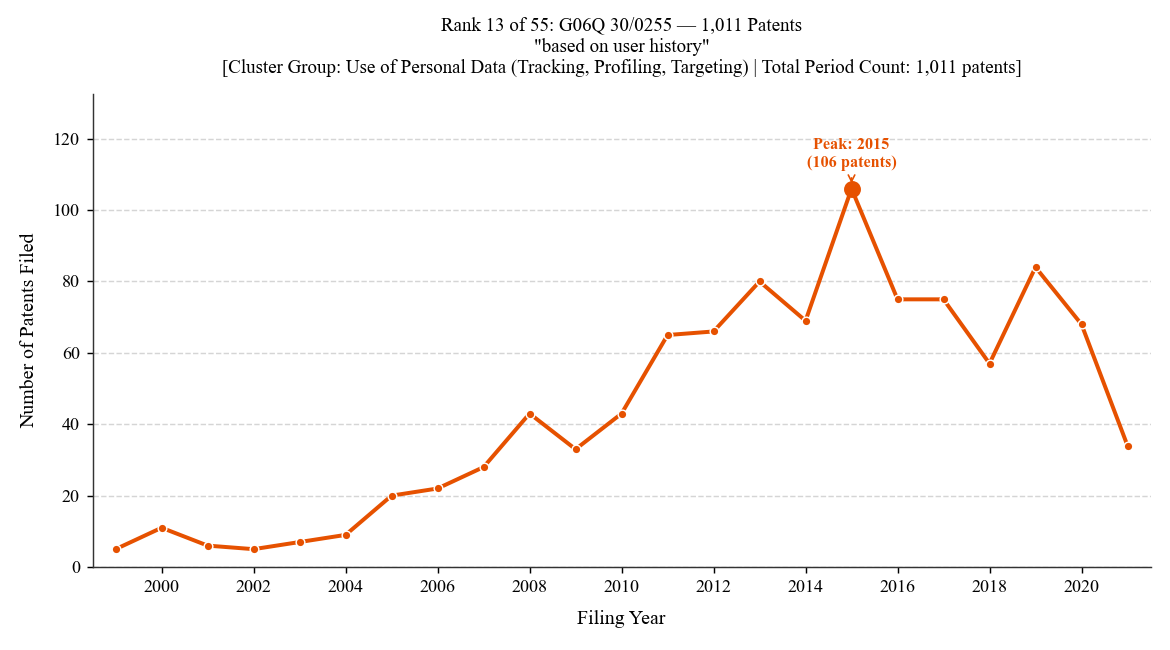

In [44]:
# Rank 13: G06Q 30/0255 (1,011 patents)
# Peak: 2015 (106 patents) | Files: fig_rank_13_G06Q30_0255.{png,pdf,svg}


### Rank 14. G06F 2221/2107: File encryption... (965 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"File encryption"*


Rank 14: G06F 2221/2107 | Total: 965 patents | Peak: 2017 (70 patents)


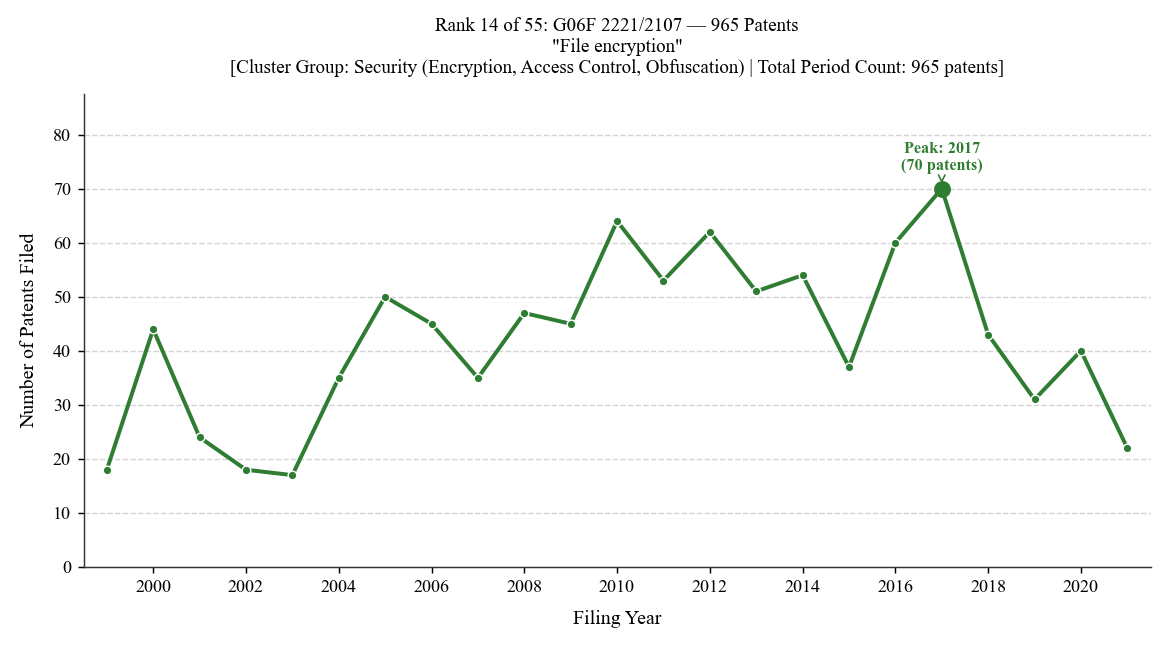

In [46]:
# Rank 14: G06F 2221/2107 (965 patents)
# Peak: 2017 (70 patents) | Files: fig_rank_14_G06F2221_2107.{png,pdf,svg}


### Rank 15. G06Q 30/0261: based on user location... (959 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"based on user location"*


Rank 15: G06Q 30/0261 | Total: 959 patents | Peak: 2016 (105 patents)


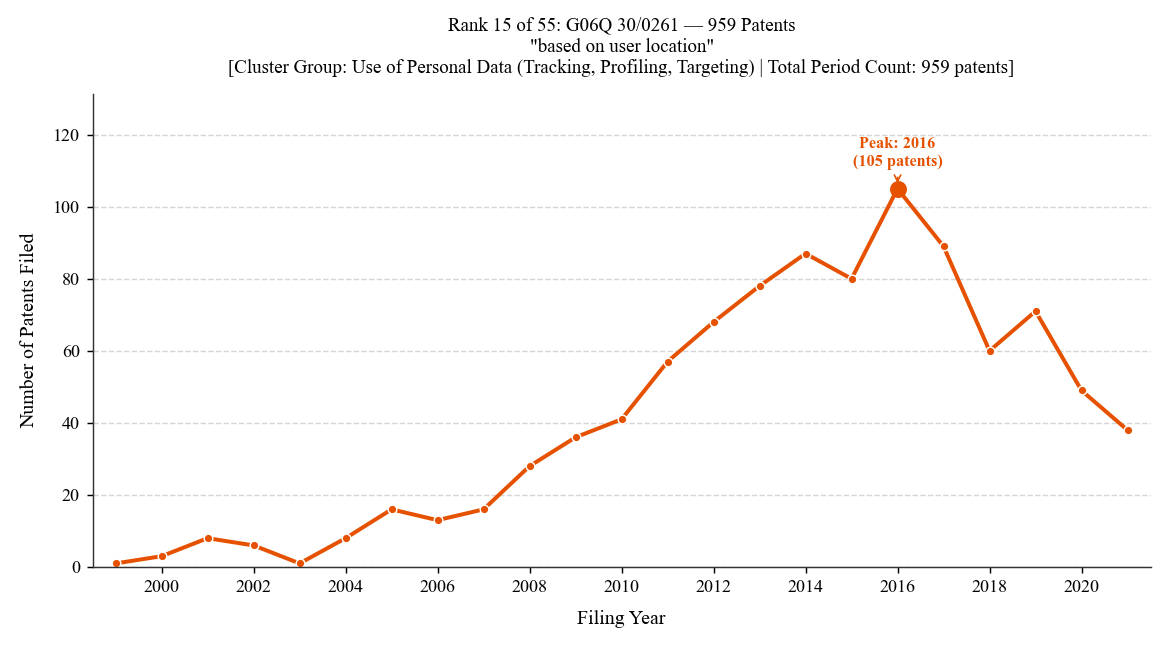

In [48]:
# Rank 15: G06Q 30/0261 (959 patents)
# Peak: 2016 (105 patents) | Files: fig_rank_15_G06Q30_0261.{png,pdf,svg}


### Rank 16. G06F 21/60: Protecting data... (886 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Protecting data"*


Rank 16: G06F 21/60 | Total: 886 patents | Peak: 2013 (164 patents)


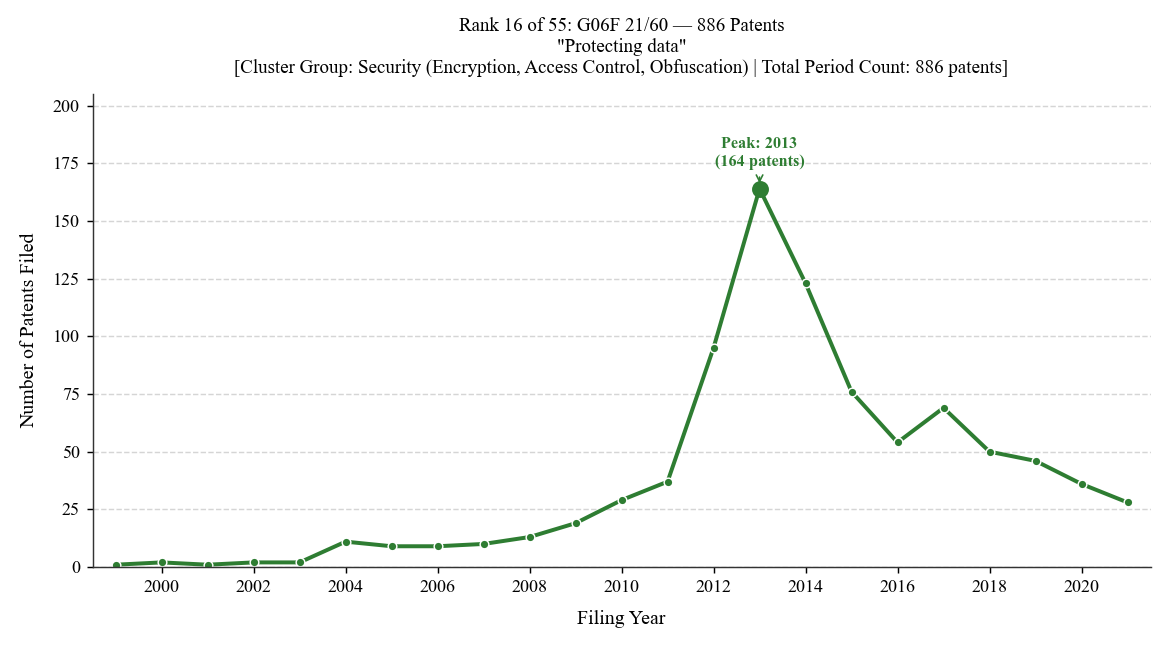

In [50]:
# Rank 16: G06F 21/60 (886 patents)
# Peak: 2013 (164 patents) | Files: fig_rank_16_G06F21_60.{png,pdf,svg}


### Rank 17. H04L 63/0442: wherein the sending and receiving network entities apply asymmetric encryption, ... (875 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"wherein the sending and receiving network entities apply asymmetric encryption, i.e. different keys for encryption and decryption (cryptographic mechanisms or cryptographic arrangements for public-key encryption H04L 9/30)"*


Rank 17: H04L 63/0442 | Total: 875 patents | Peak: 2017 (122 patents)


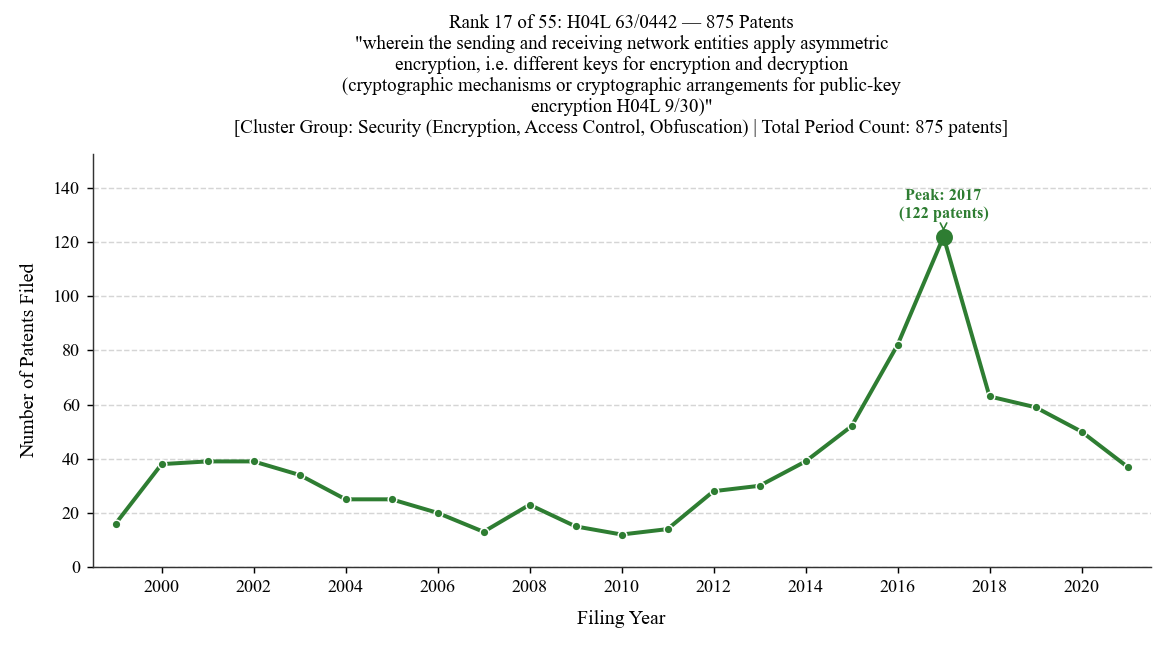

In [52]:
# Rank 17: H04L 63/0442 (875 patents)
# Peak: 2017 (122 patents) | Files: fig_rank_17_H04L63_0442.{png,pdf,svg}


### Rank 18. G06F 21/6254: by anonymising data, e.g. decorrelating personal data from the owner's identific... (819 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"by anonymising data, e.g. decorrelating personal data from the owner's identification"*


Rank 18: G06F 21/6254 | Total: 819 patents | Peak: 2019 (133 patents)


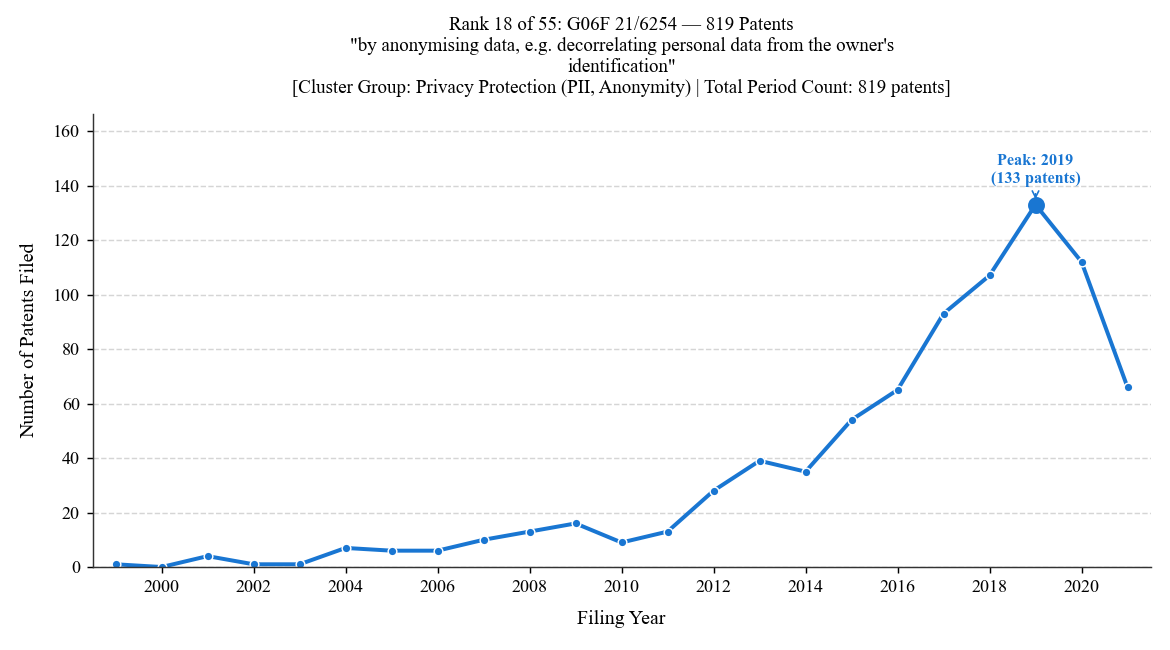

In [54]:
# Rank 18: G06F 21/6254 (819 patents)
# Peak: 2019 (133 patents) | Files: fig_rank_18_G06F21_6254.{png,pdf,svg}


### Rank 19. G06F 21/78: to assure secure storage of data (address-based protection against unauthorised ... (775 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"to assure secure storage of data (address-based protection against unauthorised use of memory G06F 12/14; record carriers for use with machines and with at least a part designed to carry digital markings G06K 19/00)"*


Rank 19: G06F 21/78 | Total: 775 patents | Peak: 2017 (64 patents)


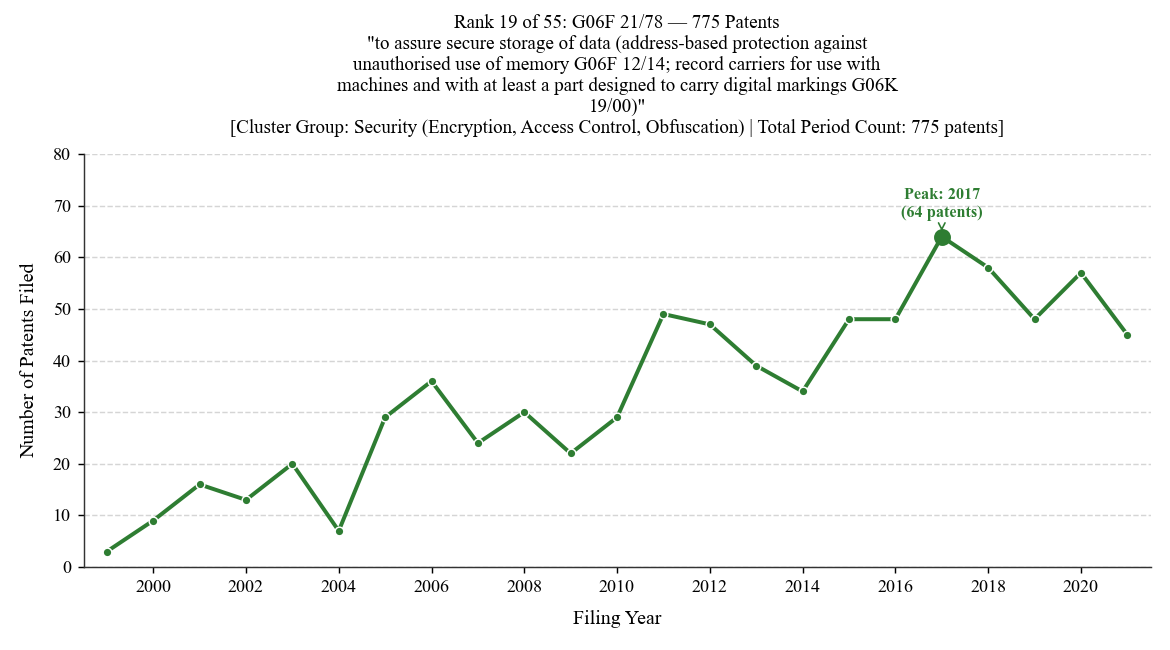

In [56]:
# Rank 19: G06F 21/78 (775 patents)
# Peak: 2017 (64 patents) | Files: fig_rank_19_G06F21_78.{png,pdf,svg}


### Rank 20. H04L 63/0435: wherein the sending and receiving network entities apply symmetric encryption, i... (747 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"wherein the sending and receiving network entities apply symmetric encryption, i.e. same key used for encryption and decryption (cryptographic mechanisms or cryptographic arrangements for symmetric key encryption H04L 9/06)"*


Rank 20: H04L 63/0435 | Total: 747 patents | Peak: 2017 (105 patents)


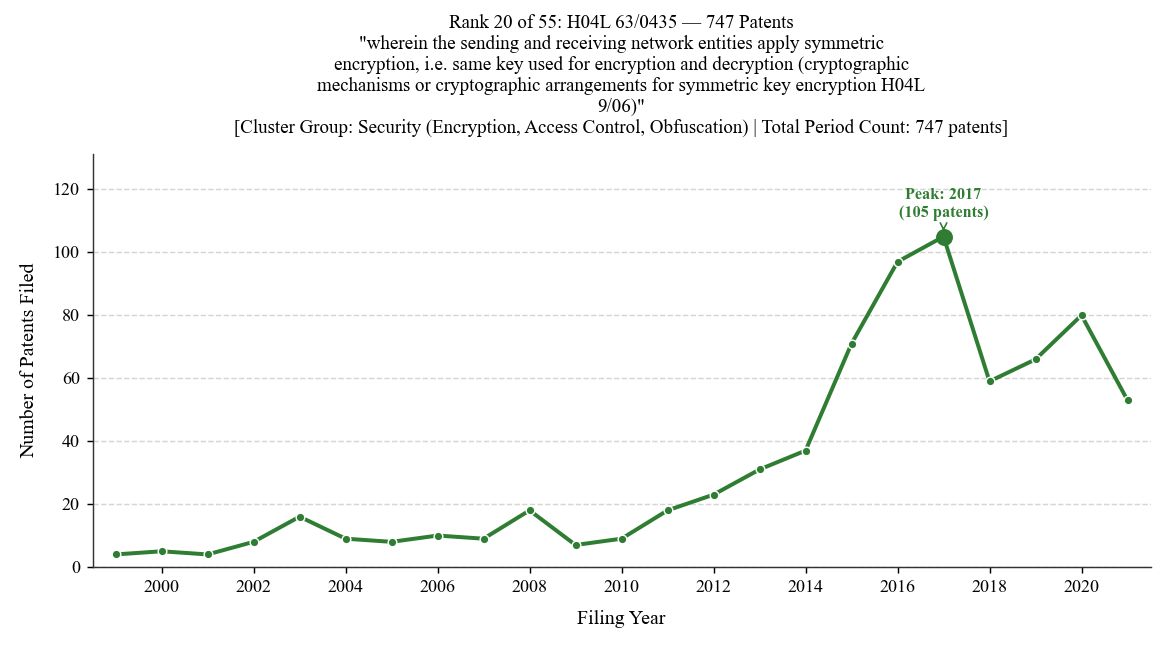

In [58]:
# Rank 20: H04L 63/0435 (747 patents)
# Peak: 2017 (105 patents) | Files: fig_rank_20_H04L63_0435.{png,pdf,svg}


### Rank 21. G06F 21/606: by securing the transmission between two devices or processes... (746 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"by securing the transmission between two devices or processes"*


Rank 21: G06F 21/606 | Total: 746 patents | Peak: 2015 (59 patents)


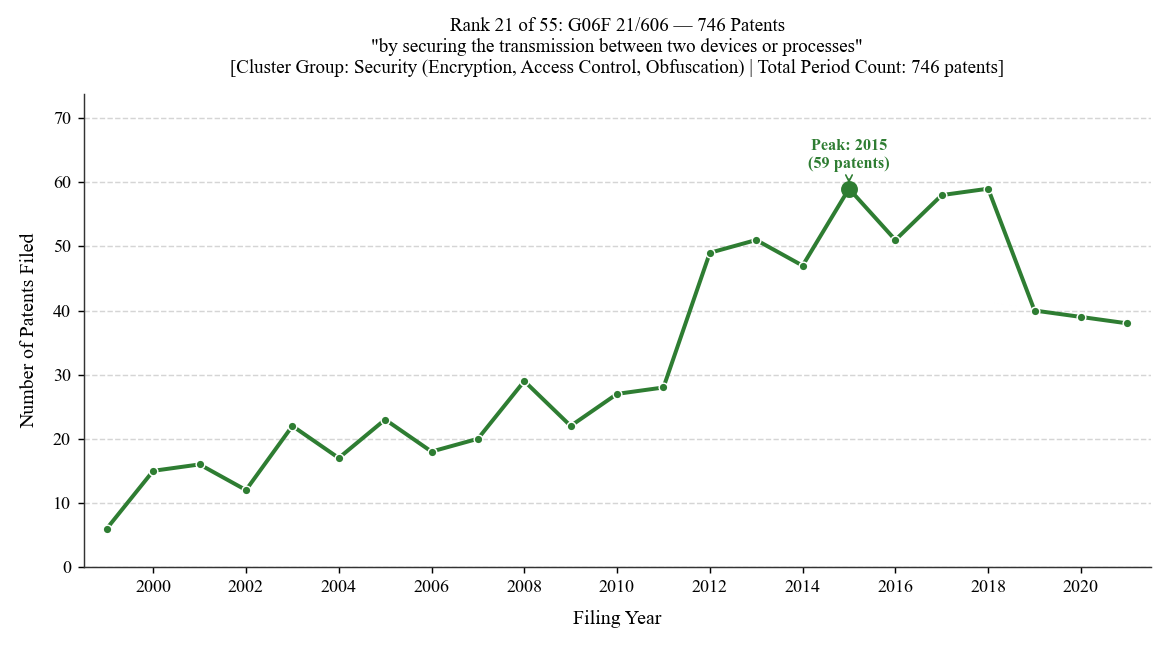

In [60]:
# Rank 21: G06F 21/606 (746 patents)
# Peak: 2015 (59 patents) | Files: fig_rank_21_G06F21_606.{png,pdf,svg}


### Rank 22. G06Q 20/385: using an alias or single-use codes... (691 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"using an alias or single-use codes"*


Rank 22: G06Q 20/385 | Total: 691 patents | Peak: 2019 (91 patents)


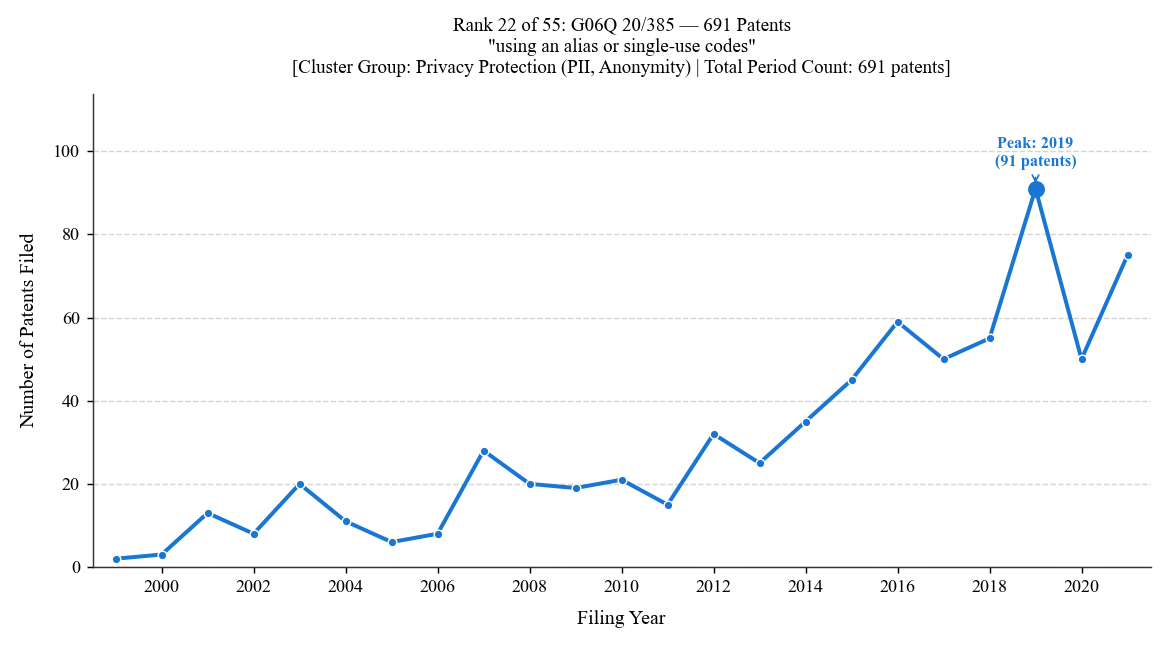

In [62]:
# Rank 22: G06Q 20/385 (691 patents)
# Peak: 2019 (91 patents) | Files: fig_rank_22_G06Q20_385.{png,pdf,svg}


### Rank 23. H04L 63/04: for providing a confidential data exchange among entities communicating through ... (583 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"for providing a confidential data exchange among entities communicating through data packet networks"*


Rank 23: H04L 63/04 | Total: 583 patents | Peak: 2015 (51 patents)


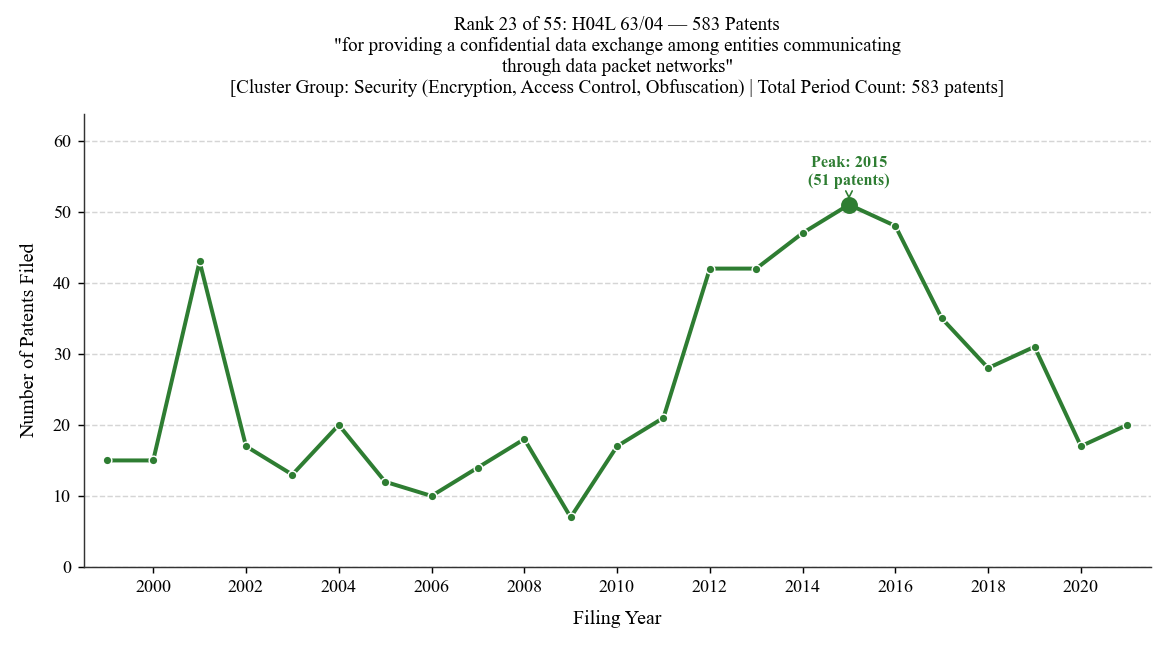

In [64]:
# Rank 23: H04L 63/04 (583 patents)
# Peak: 2015 (51 patents) | Files: fig_rank_23_H04L63_04.{png,pdf,svg}


### Rank 24. G06Q 50/265: Personal security, identity or safety... (469 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"Personal security, identity or safety"*


Rank 24: G06Q 50/265 | Total: 469 patents | Peak: 2020 (126 patents)


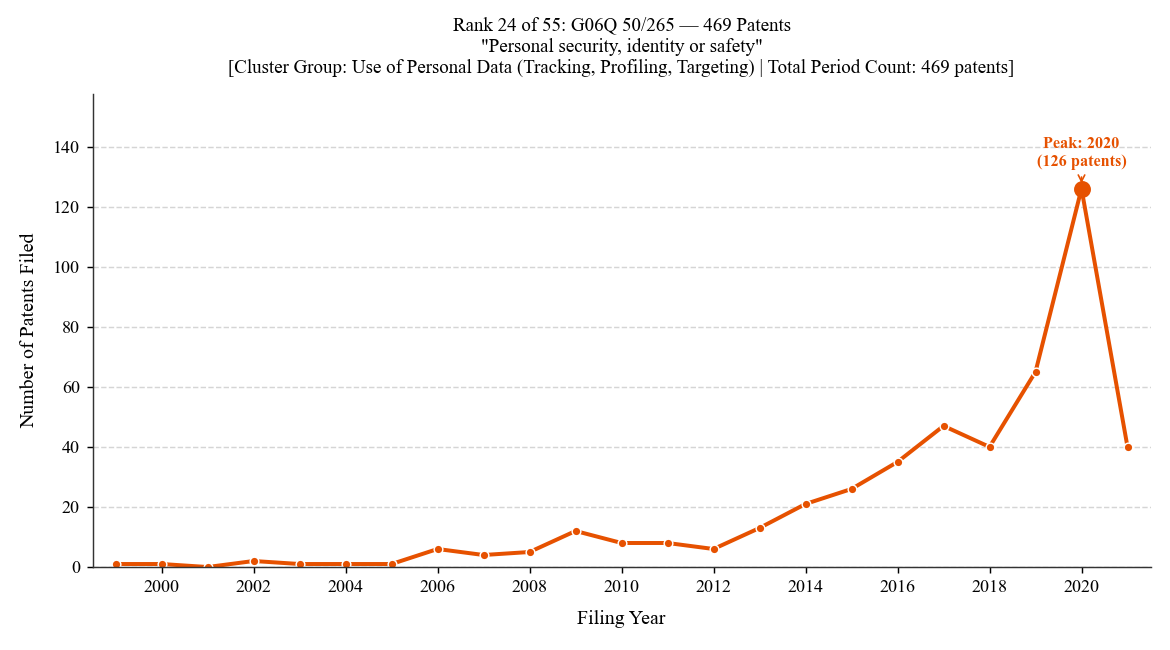

In [66]:
# Rank 24: G06Q 50/265 (469 patents)
# Peak: 2020 (126 patents) | Files: fig_rank_24_G06Q50_265.{png,pdf,svg}


### Rank 25. G06Q 10/063114: Status monitoring or status determination for a person or group... (467 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"Status monitoring or status determination for a person or group"*


Rank 25: G06Q 10/063114 | Total: 467 patents | Peak: 2021 (46 patents)


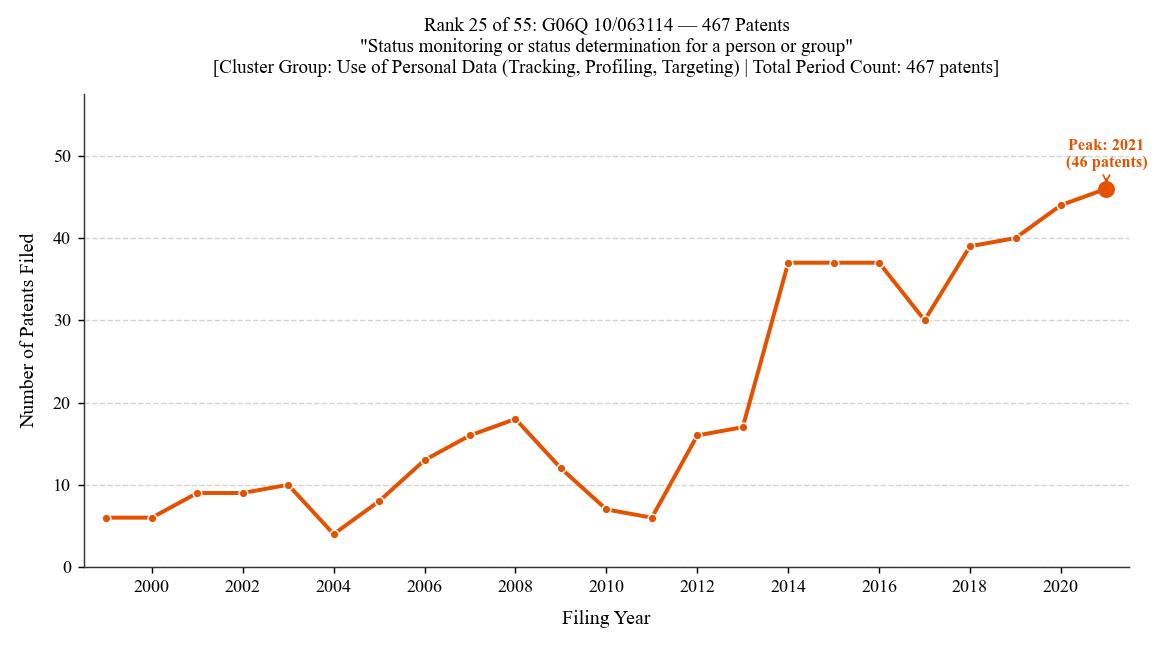

In [68]:
# Rank 25: G06Q 10/063114 (467 patents)
# Peak: 2021 (46 patents) | Files: fig_rank_25_G06Q10_063114.{png,pdf,svg}


### Rank 26. G06F 11/3438: monitoring of user actions (tracking the activity of the user H04L 67/535)... (457 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"monitoring of user actions (tracking the activity of the user H04L 67/535)"*


Rank 26: G06F 11/3438 | Total: 457 patents | Peak: 2020 (51 patents)


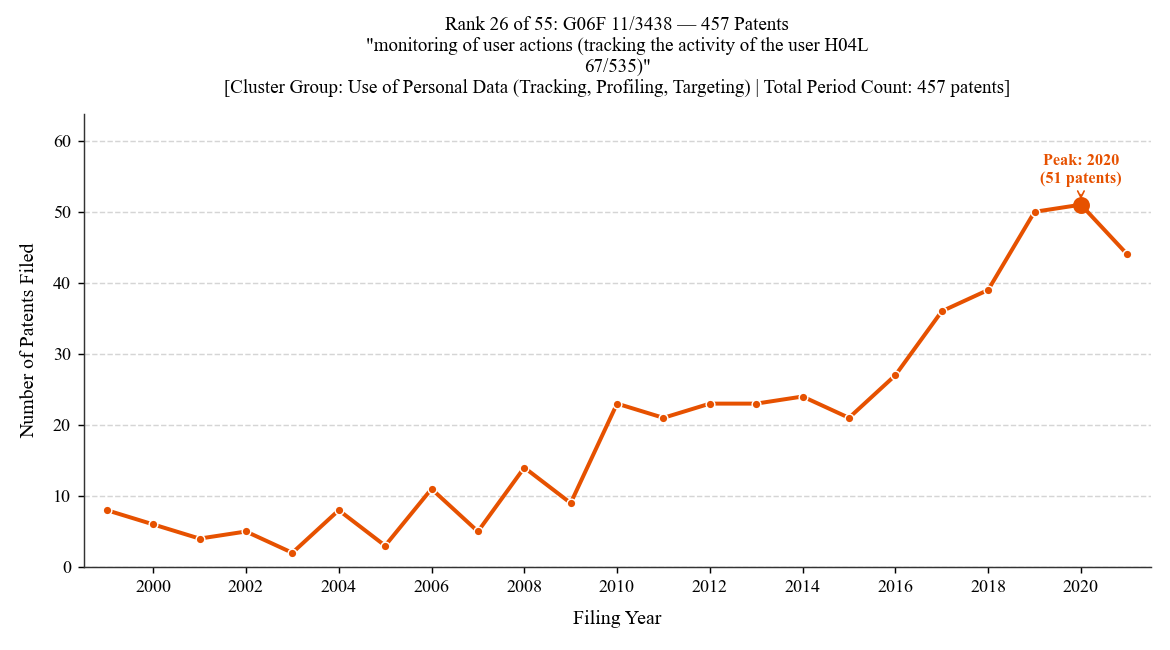

In [70]:
# Rank 26: G06F 11/3438 (457 patents)
# Peak: 2020 (51 patents) | Files: fig_rank_26_G06F11_3438.{png,pdf,svg}


### Rank 27. G06F 2221/2143: Clearing memory, e.g. to prevent the data from being stolen... (445 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Clearing memory, e.g. to prevent the data from being stolen"*


Rank 27: G06F 2221/2143 | Total: 445 patents | Peak: 2013 (48 patents)


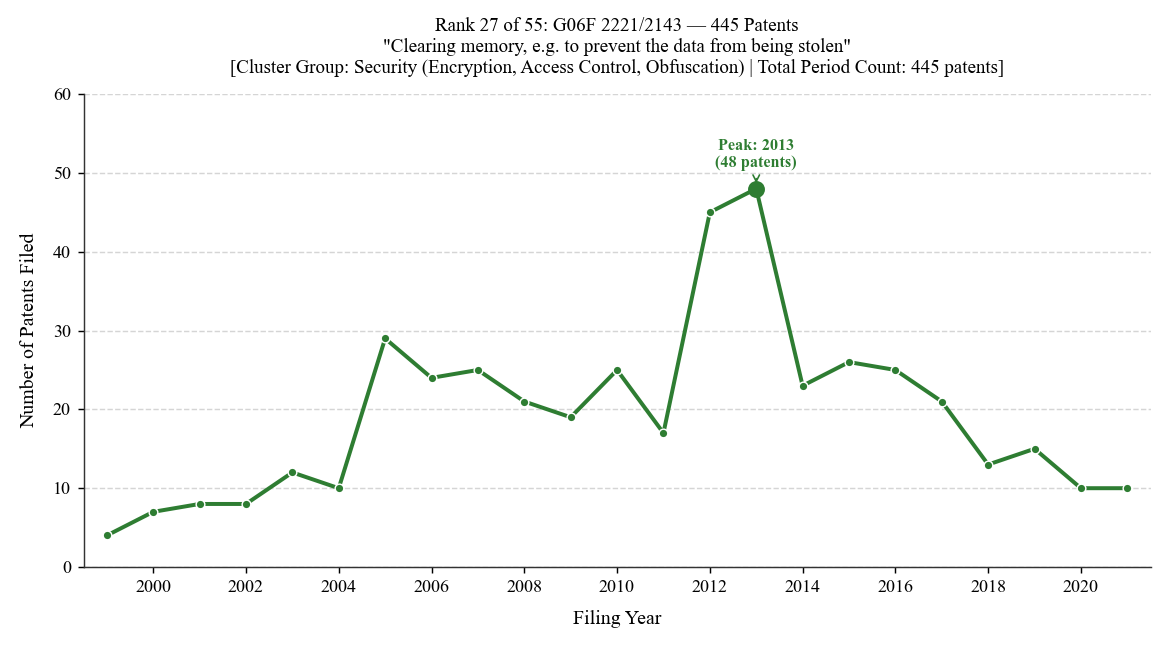

In [72]:
# Rank 27: G06F 2221/2143 (445 patents)
# Peak: 2013 (48 patents) | Files: fig_rank_27_G06F2221_2143.{png,pdf,svg}


### Rank 28. G06F 21/6263: during internet communication, e.g. revealing personal data from cookies... (383 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"during internet communication, e.g. revealing personal data from cookies"*


Rank 28: G06F 21/6263 | Total: 383 patents | Peak: 2016 (41 patents)


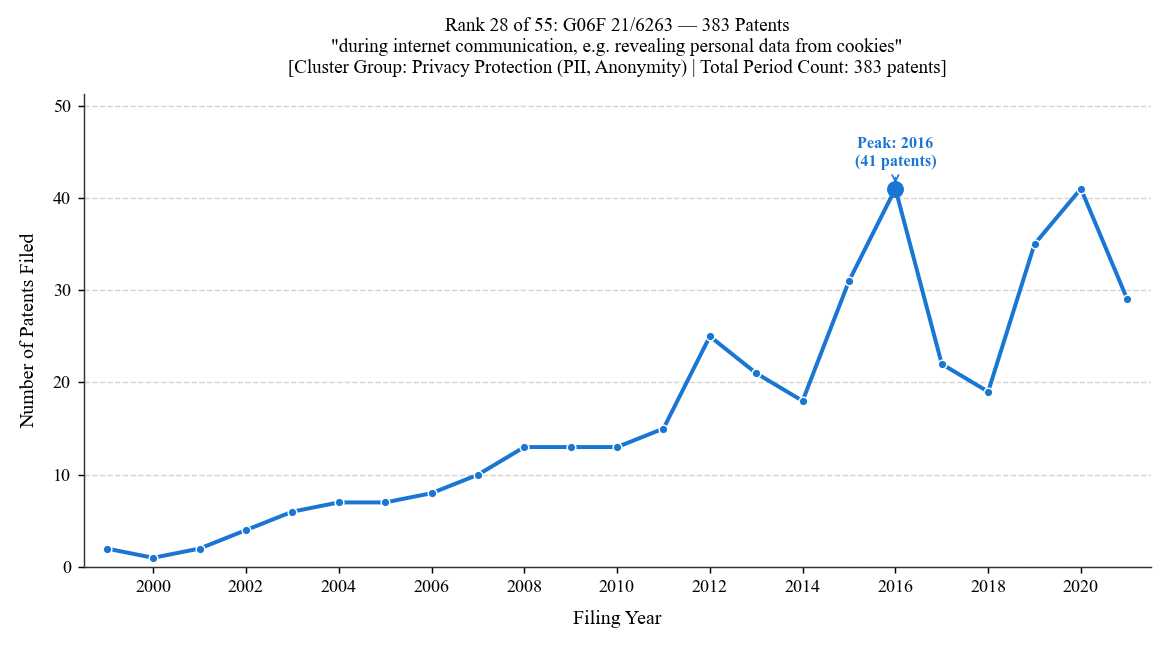

In [74]:
# Rank 28: G06F 21/6263 (383 patents)
# Peak: 2016 (41 patents) | Files: fig_rank_28_G06F21_6263.{png,pdf,svg}


### Rank 29. G06F 3/0623: in relation to content... (377 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"in relation to content"*


Rank 29: G06F 3/0623 | Total: 377 patents | Peak: 2017 (49 patents)


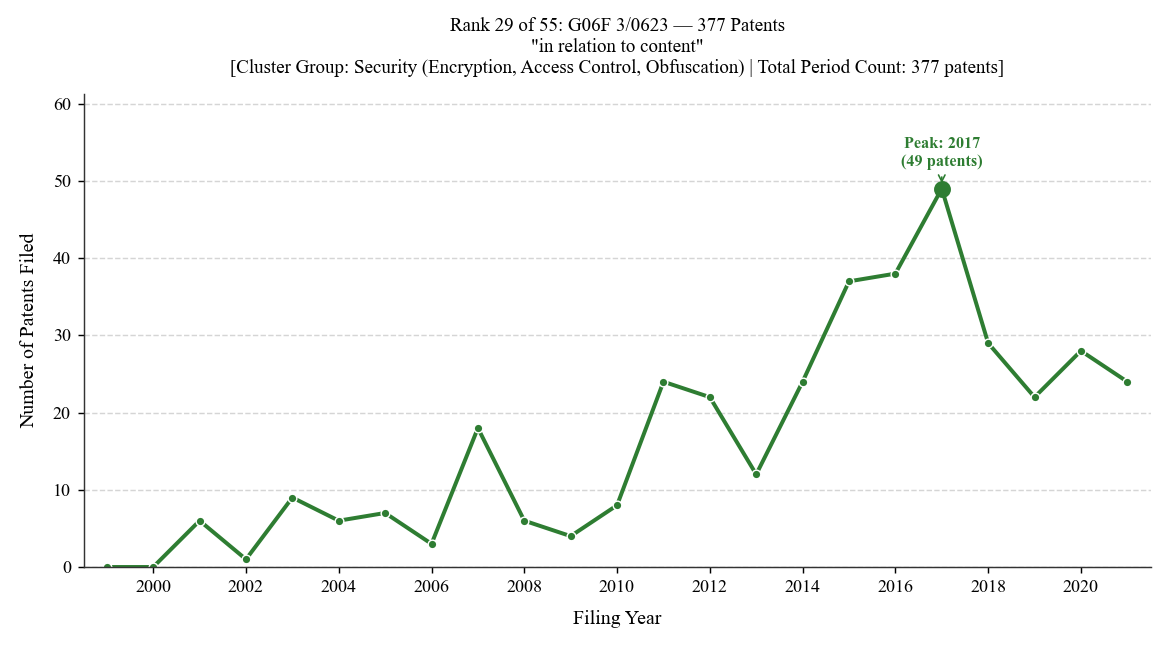

In [76]:
# Rank 29: G06F 3/0623 (377 patents)
# Peak: 2017 (49 patents) | Files: fig_rank_29_G06F3_0623.{png,pdf,svg}


### Rank 30. H04L 67/535: Tracking the activity of the user (network monitoring arrangements H04L 43/00; r... (354 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"Tracking the activity of the user (network monitoring arrangements H04L 43/00; recording of computer activity G06F 11/34)"*


Rank 30: H04L 67/535 | Total: 354 patents | Peak: 2021 (164 patents)


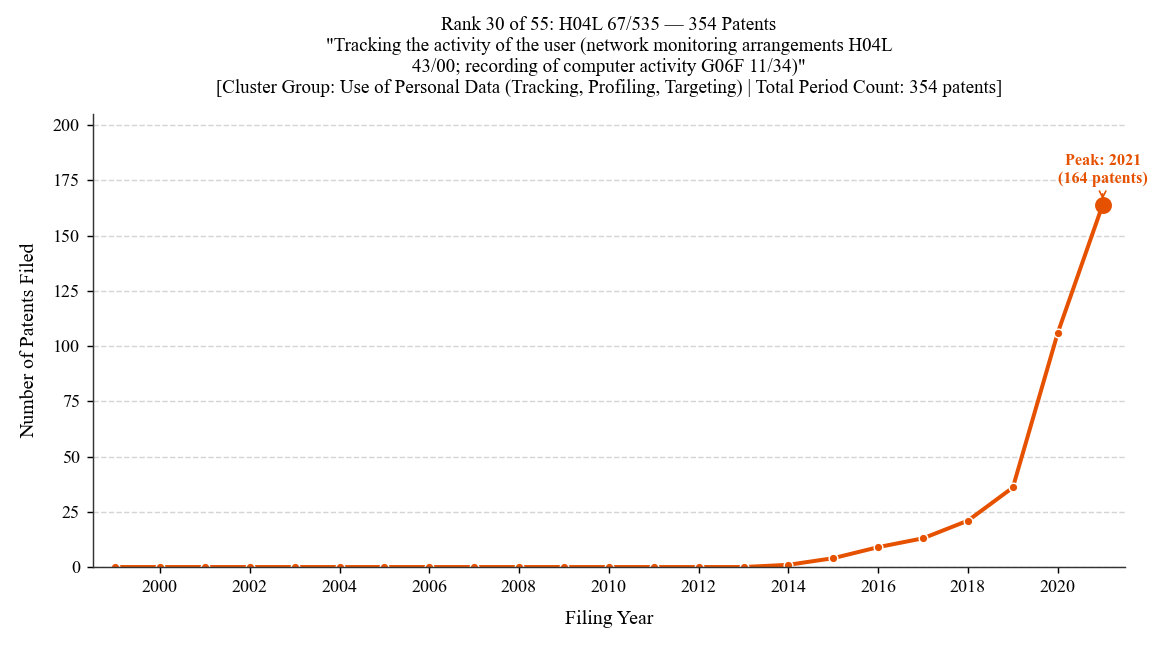

In [78]:
# Rank 30: H04L 67/535 (354 patents)
# Peak: 2021 (164 patents) | Files: fig_rank_30_H04L67_535.{png,pdf,svg}


### Rank 31. G06F 21/84: output devices, e.g. displays or monitors... (316 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"output devices, e.g. displays or monitors"*


Rank 31: G06F 21/84 | Total: 316 patents | Peak: 2017 (25 patents)


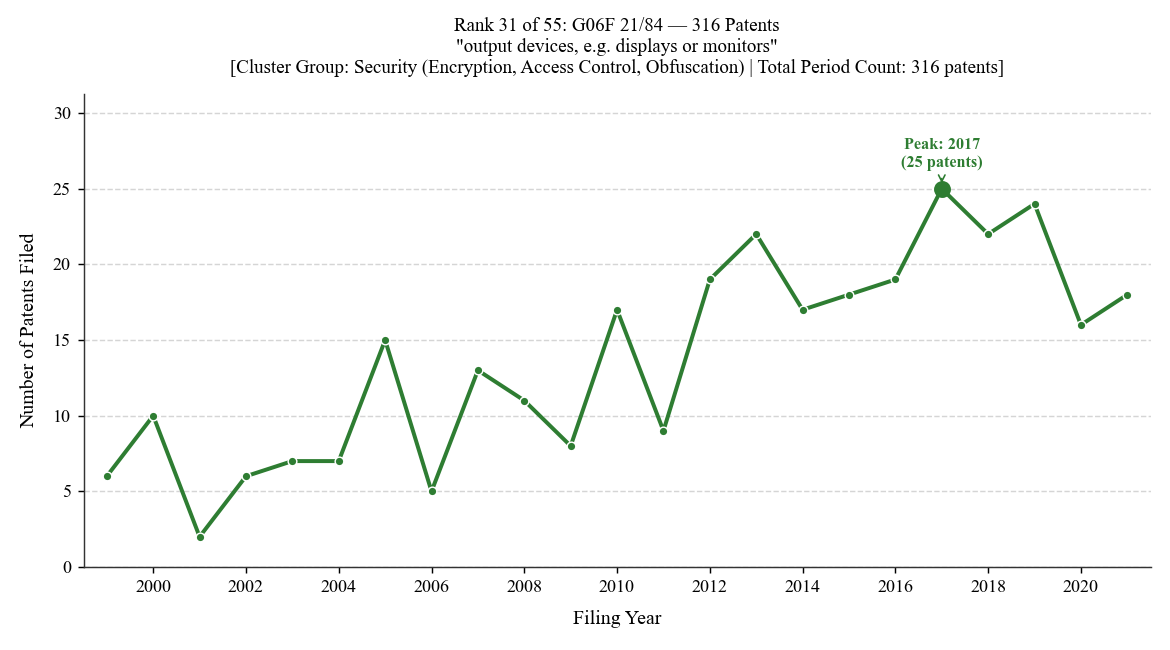

In [80]:
# Rank 31: G06F 21/84 (316 patents)
# Peak: 2017 (25 patents) | Files: fig_rank_31_G06F21_84.{png,pdf,svg}


### Rank 32. G06Q 30/0271: Personalized advertisement... (311 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"Personalized advertisement"*


Rank 32: G06Q 30/0271 | Total: 311 patents | Peak: 2018 (28 patents)


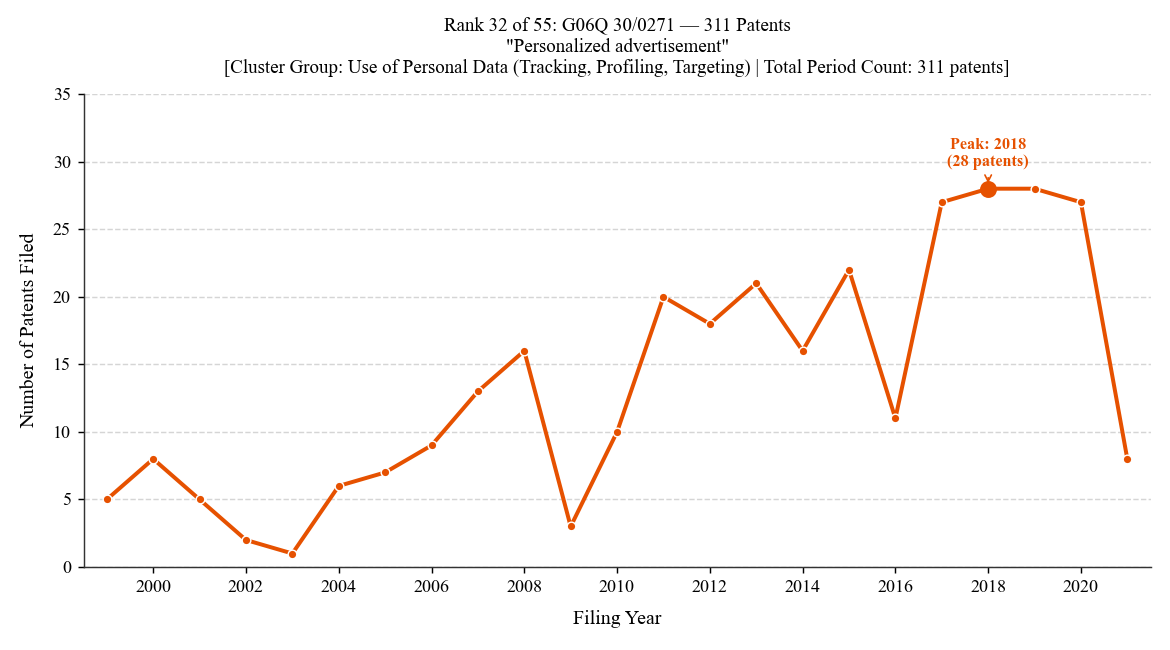

In [82]:
# Rank 32: G06Q 30/0271 (311 patents)
# Peak: 2018 (28 patents) | Files: fig_rank_32_G06Q30_0271.{png,pdf,svg}


### Rank 33. H04L 63/0407: wherein the identity of one or more communicating identities is hidden (cryptogr... (296 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"wherein the identity of one or more communicating identities is hidden (cryptographic mechanisms or cryptographic arrangements for anonymous credentials or for identity based cryptographic systems H04L 9/00)"*


Rank 33: H04L 63/0407 | Total: 296 patents | Peak: 2013 (26 patents)


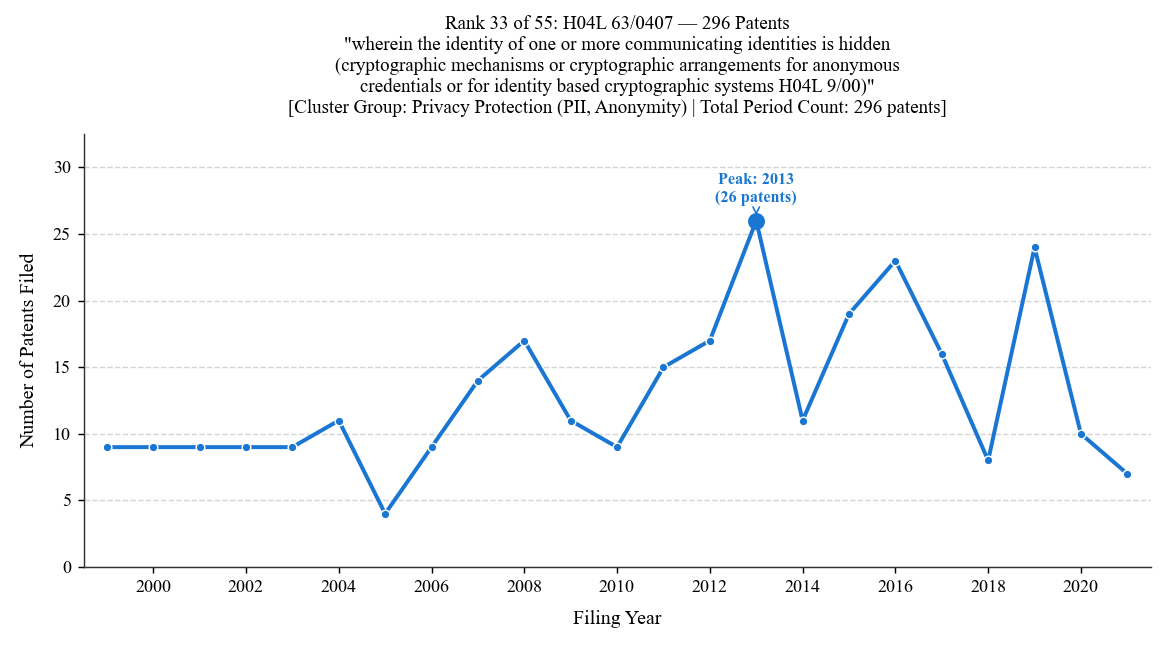

In [84]:
# Rank 33: H04L 63/0407 (296 patents)
# Peak: 2013 (26 patents) | Files: fig_rank_33_H04L63_0407.{png,pdf,svg}


### Rank 34. H04L 63/0492: by using a location-limited connection, e.g. near-field communication or limited... (295 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"by using a location-limited connection, e.g. near-field communication or limited proximity of entities"*


Rank 34: H04L 63/0492 | Total: 295 patents | Peak: 2017 (30 patents)


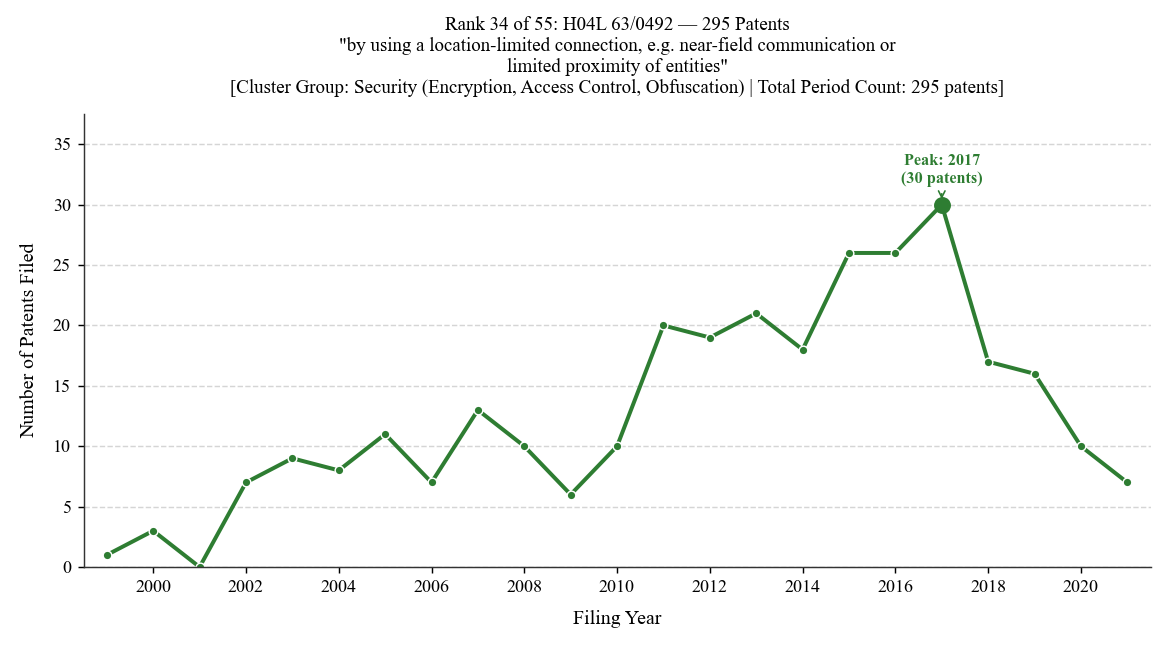

In [86]:
# Rank 34: H04L 63/0492 (295 patents)
# Peak: 2017 (30 patents) | Files: fig_rank_34_H04L63_0492.{png,pdf,svg}


### Rank 35. G06Q 20/363: with the personal data of a user... (294 Patents)
- **Group**: Use of Personal Data (Tracking, Profiling, Targeting)
- **Full Definition**: *"with the personal data of a user"*


Rank 35: G06Q 20/363 | Total: 294 patents | Peak: 2019 (31 patents)


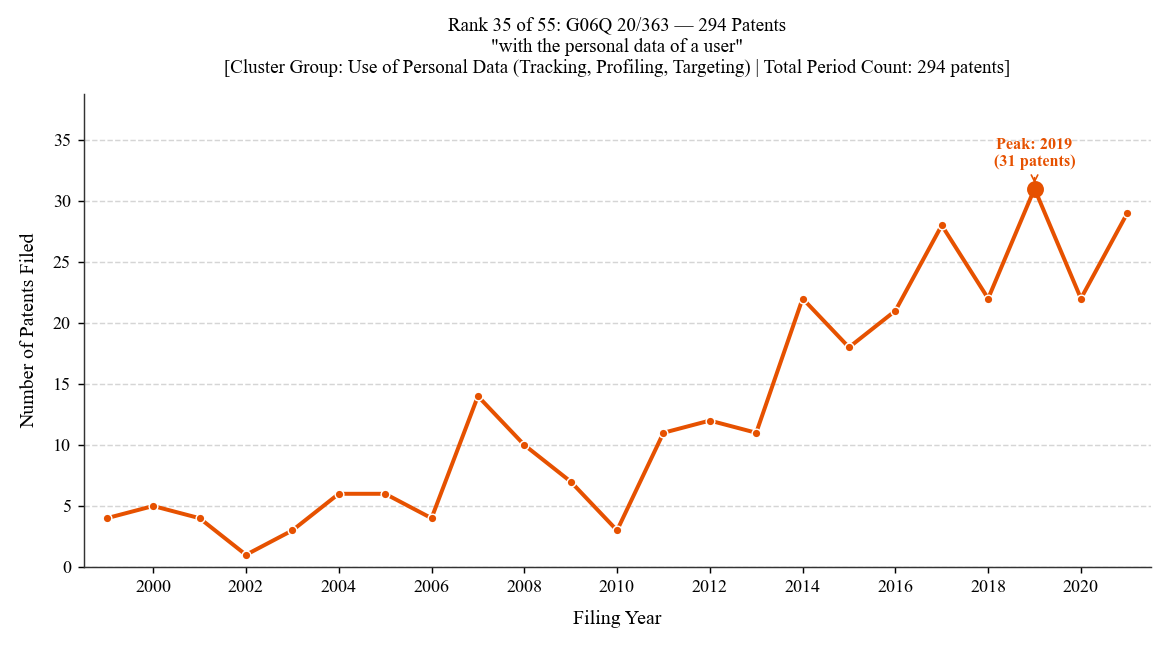

In [88]:
# Rank 35: G06Q 20/363 (294 patents)
# Peak: 2019 (31 patents) | Files: fig_rank_35_G06Q20_363.{png,pdf,svg}


### Rank 36. H04L 63/0421: Anonymous communication, i.e. the party's identifiers are hidden from the other ... (291 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"Anonymous communication, i.e. the party's identifiers are hidden from the other party or parties, e.g. using an anonymizer"*


Rank 36: H04L 63/0421 | Total: 291 patents | Peak: 2017 (32 patents)


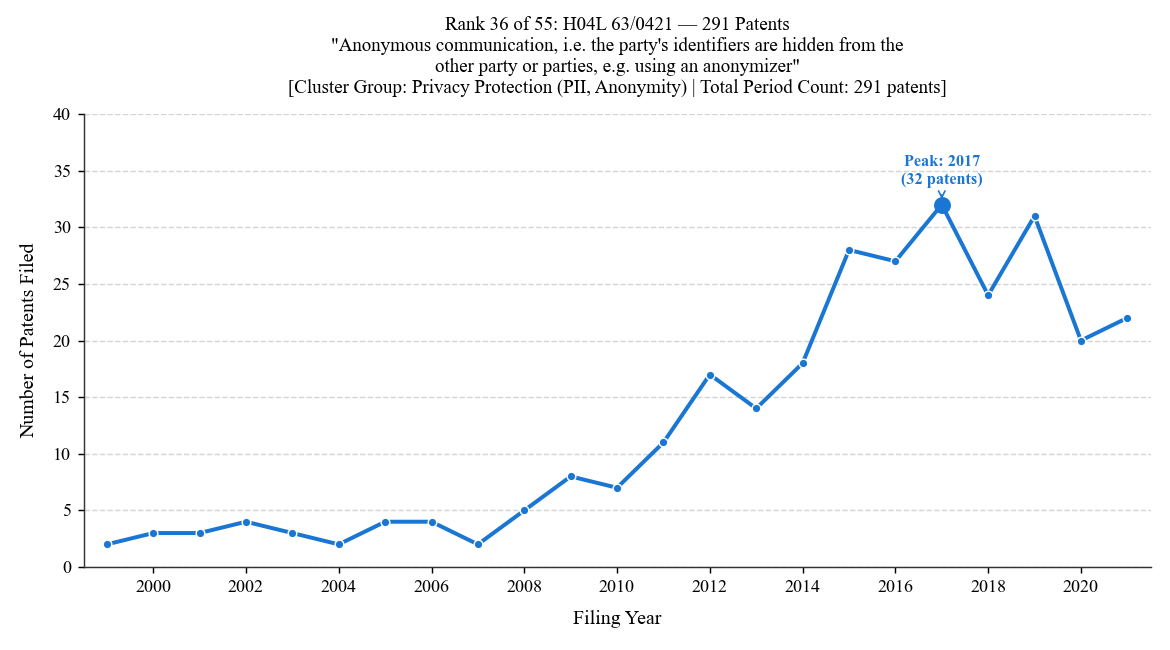

In [90]:
# Rank 36: H04L 63/0421 (291 patents)
# Peak: 2017 (32 patents) | Files: fig_rank_36_H04L63_0421.{png,pdf,svg}


### Rank 37. H04L 9/008: involving homomorphic encryption... (289 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"involving homomorphic encryption"*


Rank 37: H04L 9/008 | Total: 289 patents | Peak: 2020 (48 patents)


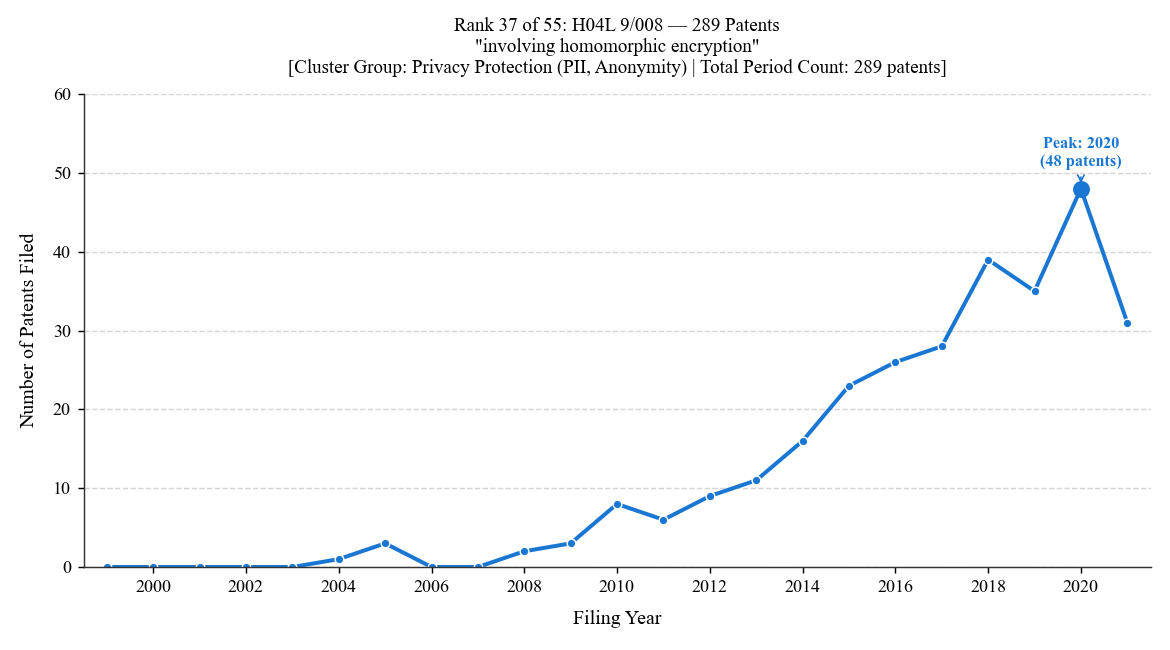

In [92]:
# Rank 37: H04L 9/008 (289 patents)
# Peak: 2020 (48 patents) | Files: fig_rank_37_H04L9_008.{png,pdf,svg}


### Rank 38. H04L 63/0485: Networking architectures for enhanced packet encryption processing, e.g. offload... (281 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Networking architectures for enhanced packet encryption processing, e.g. offloading of IPsec packet processing or efficient security association look-up"*


Rank 38: H04L 63/0485 | Total: 281 patents | Peak: 2018 (25 patents)


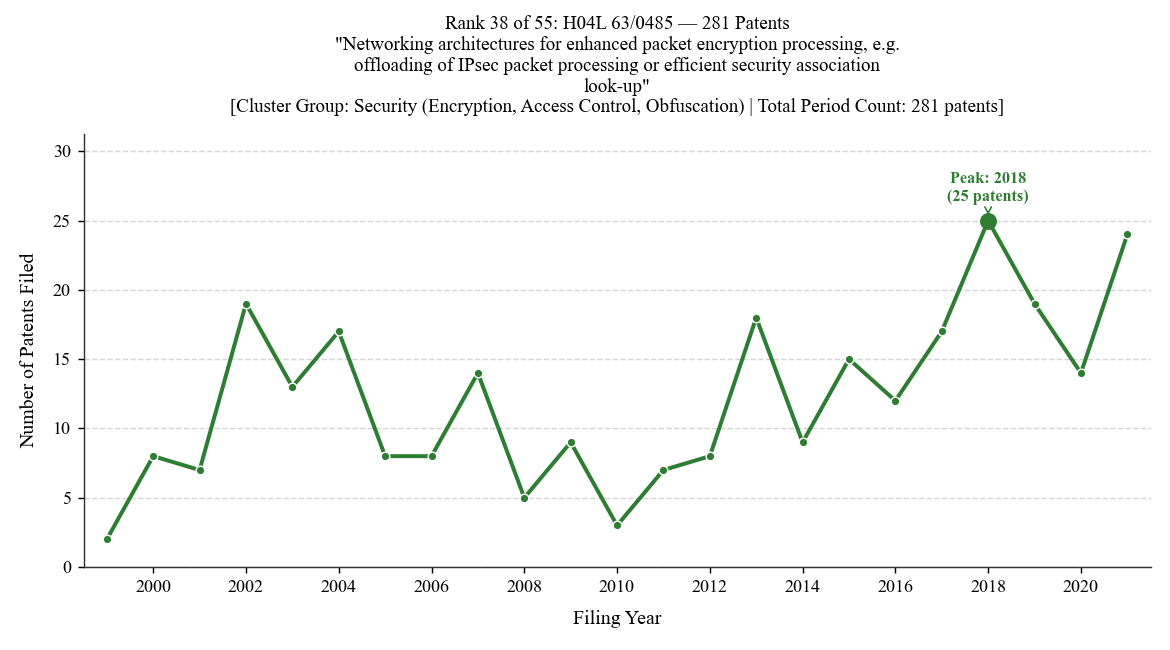

In [94]:
# Rank 38: H04L 63/0485 (281 patents)
# Peak: 2018 (25 patents) | Files: fig_rank_38_H04L63_0485.{png,pdf,svg}


### Rank 39. H04L 63/045: wherein the sending and receiving network entities apply hybrid encryption, i.e.... (247 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"wherein the sending and receiving network entities apply hybrid encryption, i.e. combination of symmetric and asymmetric encryption (cryptographic mechanisms or cryptographic arrangements using a plurality of keys or algorithms H04L 9/14)"*


Rank 39: H04L 63/045 | Total: 247 patents | Peak: 2017 (27 patents)


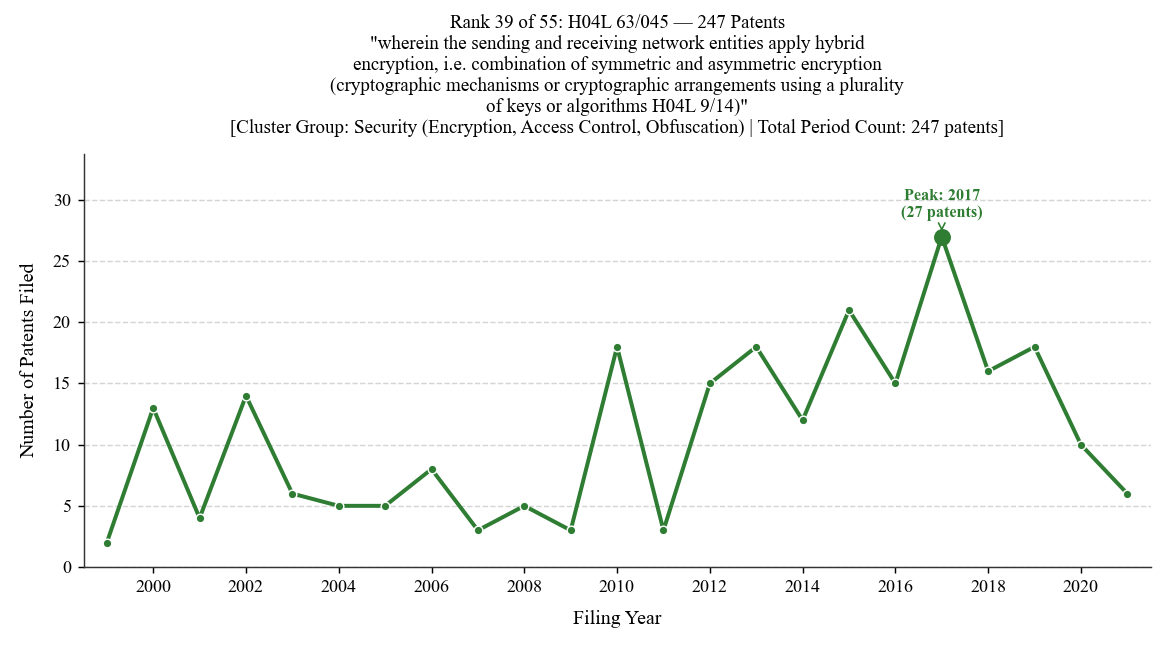

In [96]:
# Rank 39: H04L 63/045 (247 patents)
# Peak: 2017 (27 patents) | Files: fig_rank_39_H04L63_045.{png,pdf,svg}


### Rank 40. H04L 63/0471: applying encryption by an intermediary, e.g. receiving clear information at the ... (236 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"applying encryption by an intermediary, e.g. receiving clear information at the intermediary and encrypting the received information at the intermediary before forwarding"*


Rank 40: H04L 63/0471 | Total: 236 patents | Peak: 2016 (29 patents)


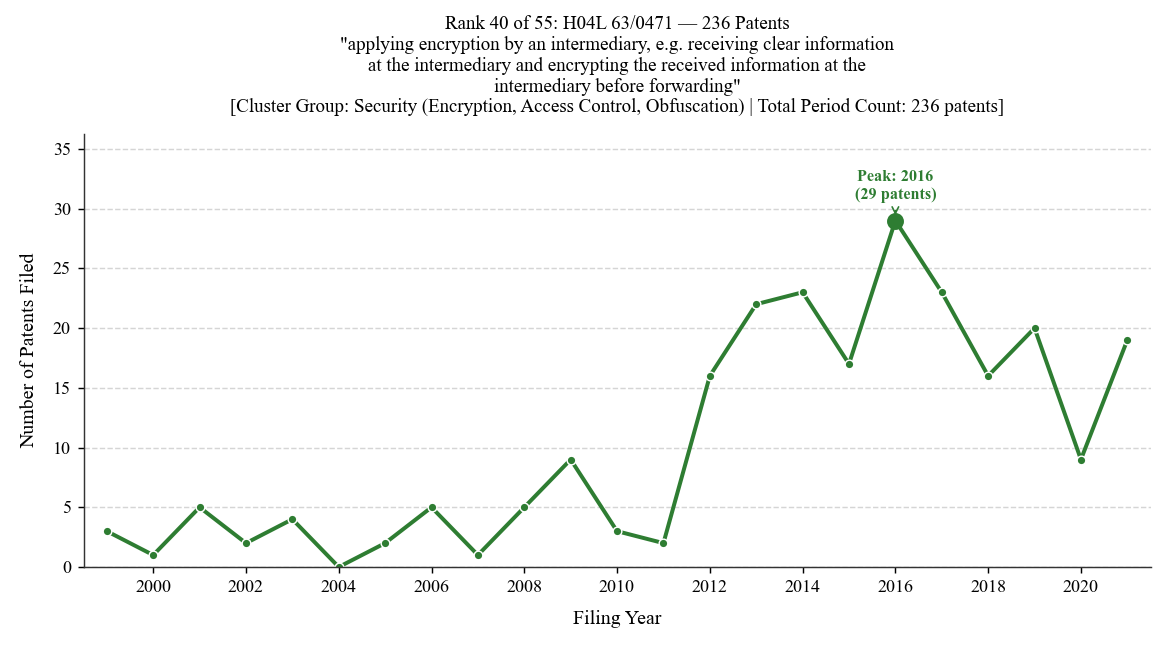

In [98]:
# Rank 40: H04L 63/0471 (236 patents)
# Peak: 2016 (29 patents) | Files: fig_rank_40_H04L63_0471.{png,pdf,svg}


### Rank 41. H04L 2209/16: Obfuscation or hiding, e.g. involving white box... (225 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Obfuscation or hiding, e.g. involving white box"*


Rank 41: H04L 2209/16 | Total: 225 patents | Peak: 2016 (25 patents)


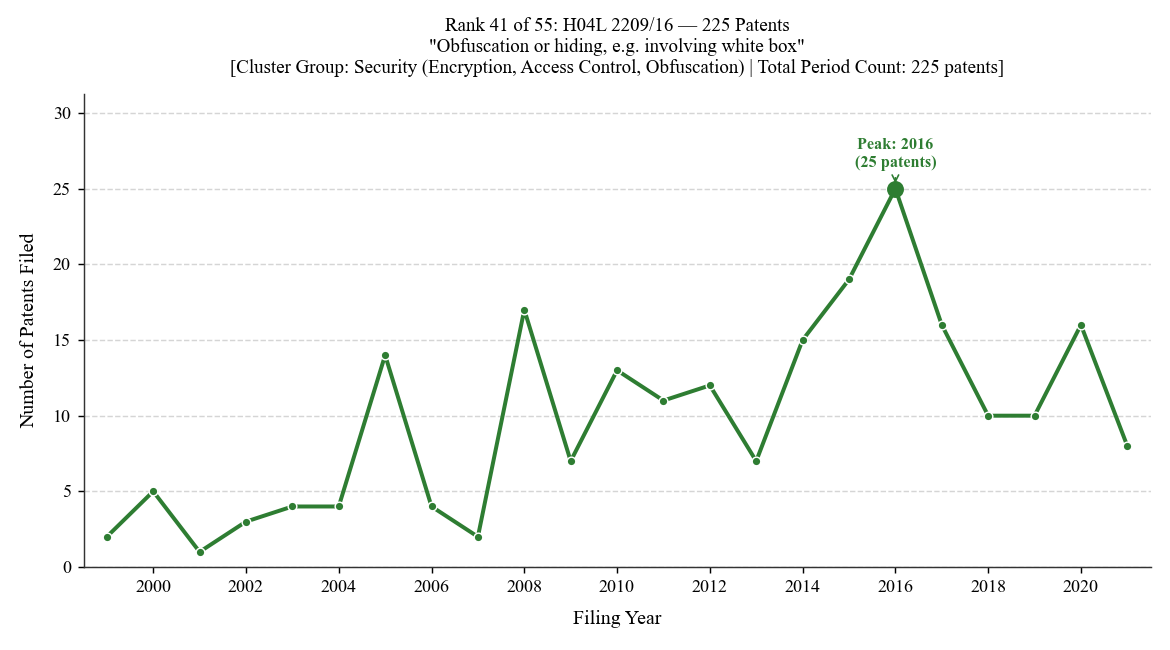

In [100]:
# Rank 41: H04L 2209/16 (225 patents)
# Peak: 2016 (25 patents) | Files: fig_rank_41_H04L2209_16.{png,pdf,svg}


### Rank 42. G06F 21/556: involving covert channels, i.e. data leakage between processes (inhibiting the a... (189 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"involving covert channels, i.e. data leakage between processes (inhibiting the analysis of circuitry or operation with measures against power attack G06F 21/755)"*


Rank 42: G06F 21/556 | Total: 189 patents | Peak: 2021 (21 patents)


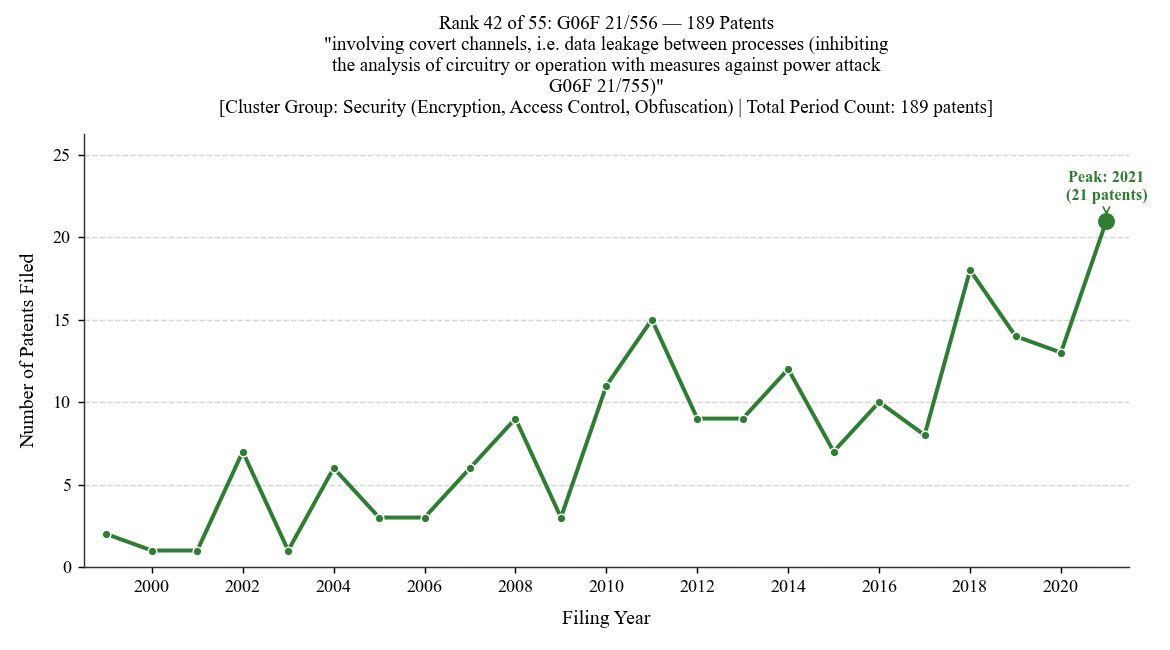

In [102]:
# Rank 42: G06F 21/556 (189 patents)
# Peak: 2021 (21 patents) | Files: fig_rank_42_G06F21_556.{png,pdf,svg}


### Rank 43. H04L 2209/42: Anonymization, e.g. involving pseudonyms... (186 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"Anonymization, e.g. involving pseudonyms"*


Rank 43: H04L 2209/42 | Total: 186 patents | Peak: 2012 (16 patents)


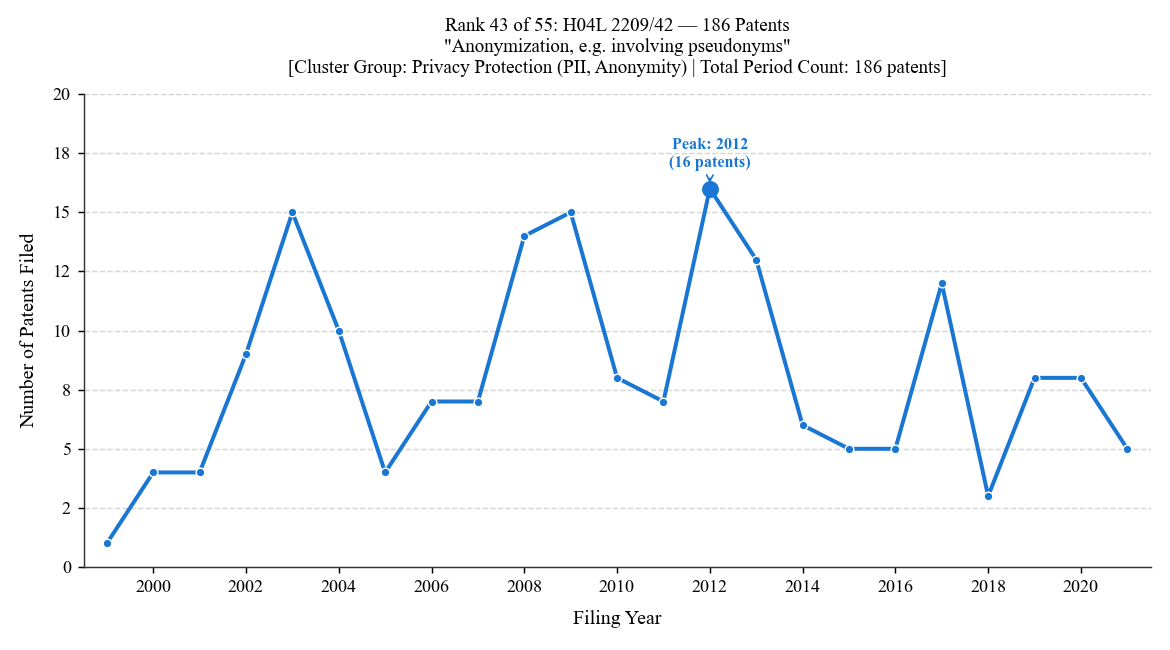

In [104]:
# Rank 43: H04L 2209/42 (186 patents)
# Peak: 2012 (16 patents) | Files: fig_rank_43_H04L2209_42.{png,pdf,svg}


### Rank 44. H04L 9/3218: using proof of knowledge, e.g. Fiat-Shamir, GQ, Schnorr, or non-interactive zero... (184 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"using proof of knowledge, e.g. Fiat-Shamir, GQ, Schnorr, or non-interactive zero-knowledge proofs"*


Rank 44: H04L 9/3218 | Total: 184 patents | Peak: 2019 (27 patents)


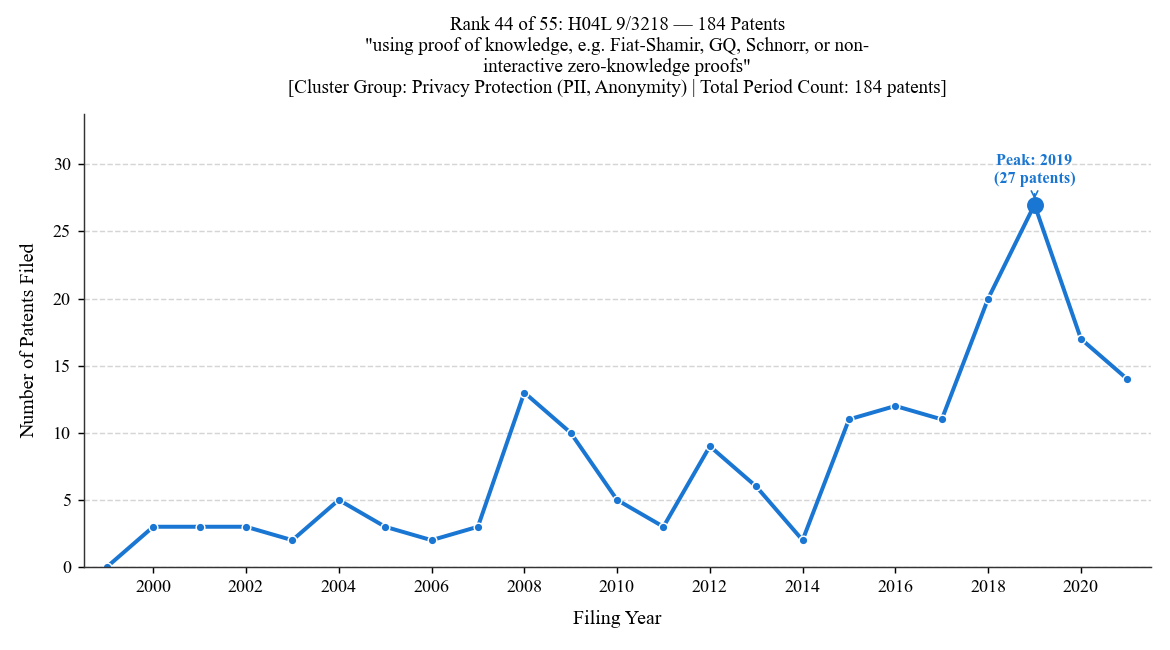

In [106]:
# Rank 44: H04L 9/3218 (184 patents)
# Peak: 2019 (27 patents) | Files: fig_rank_44_H04L9_3218.{png,pdf,svg}


### Rank 45. H04L 63/30: for supporting lawful interception, monitoring or retaining of communications or... (173 Patents)
- **Group**: Interception by Authorities
- **Full Definition**: *"for supporting lawful interception, monitoring or retaining of communications or communication related information (circuit switched telephony call monitoring H04M 3/2281)"*


Rank 45: H04L 63/30 | Total: 173 patents | Peak: 2010 (16 patents)


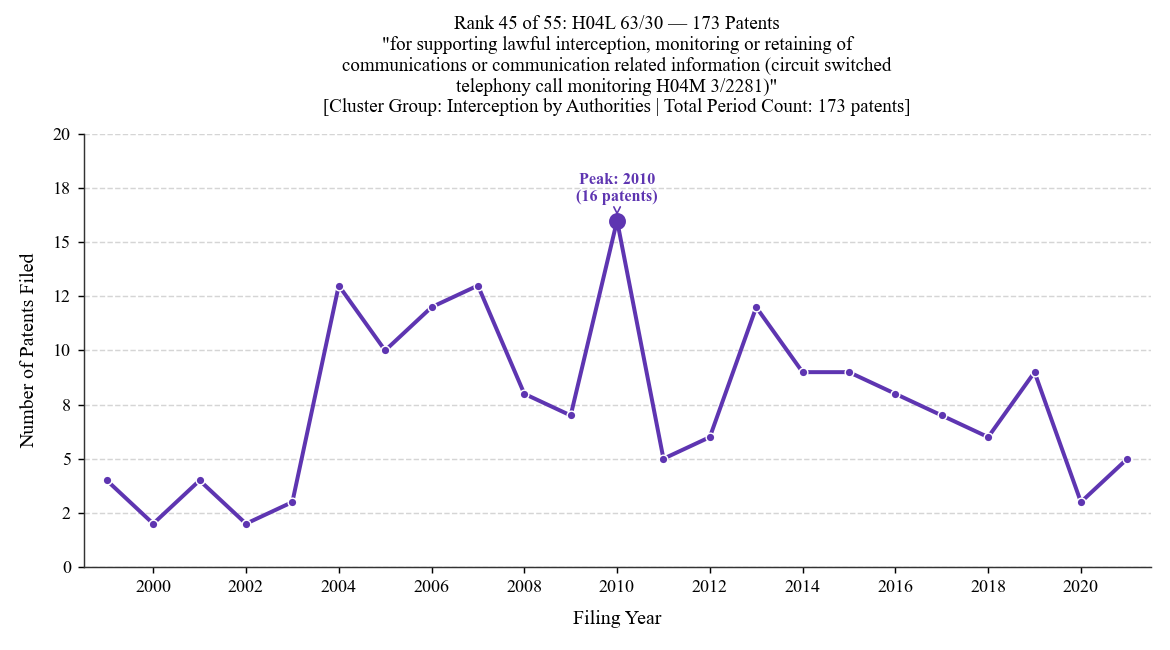

In [108]:
# Rank 45: H04L 63/30 (173 patents)
# Peak: 2010 (16 patents) | Files: fig_rank_45_H04L63_30.{png,pdf,svg}


### Rank 46. H04L 63/0464: using hop-by-hop encryption, i.e. wherein an intermediate entity decrypts the in... (156 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"using hop-by-hop encryption, i.e. wherein an intermediate entity decrypts the information and re-encrypts it before forwarding it"*


Rank 46: H04L 63/0464 | Total: 156 patents | Peak: 2013 (11 patents)


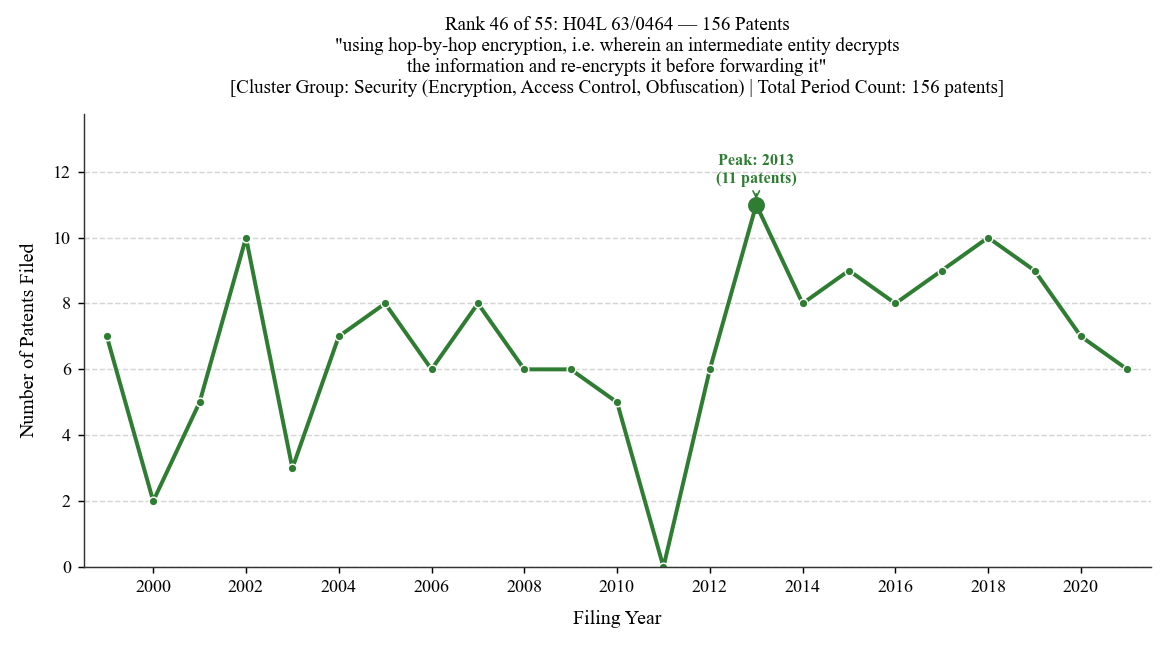

In [110]:
# Rank 46: H04L 63/0464 (156 patents)
# Peak: 2013 (11 patents) | Files: fig_rank_46_H04L63_0464.{png,pdf,svg}


### Rank 47. H04L 63/0457: wherein the sending and receiving network entities apply dynamic encryption, e.g... (154 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"wherein the sending and receiving network entities apply dynamic encryption, e.g. stream encryption (cryptographic mechanisms or cryptographic arrangements for stream encryption H04L 9/065)"*


Rank 47: H04L 63/0457 | Total: 154 patents | Peak: 2016 (19 patents)


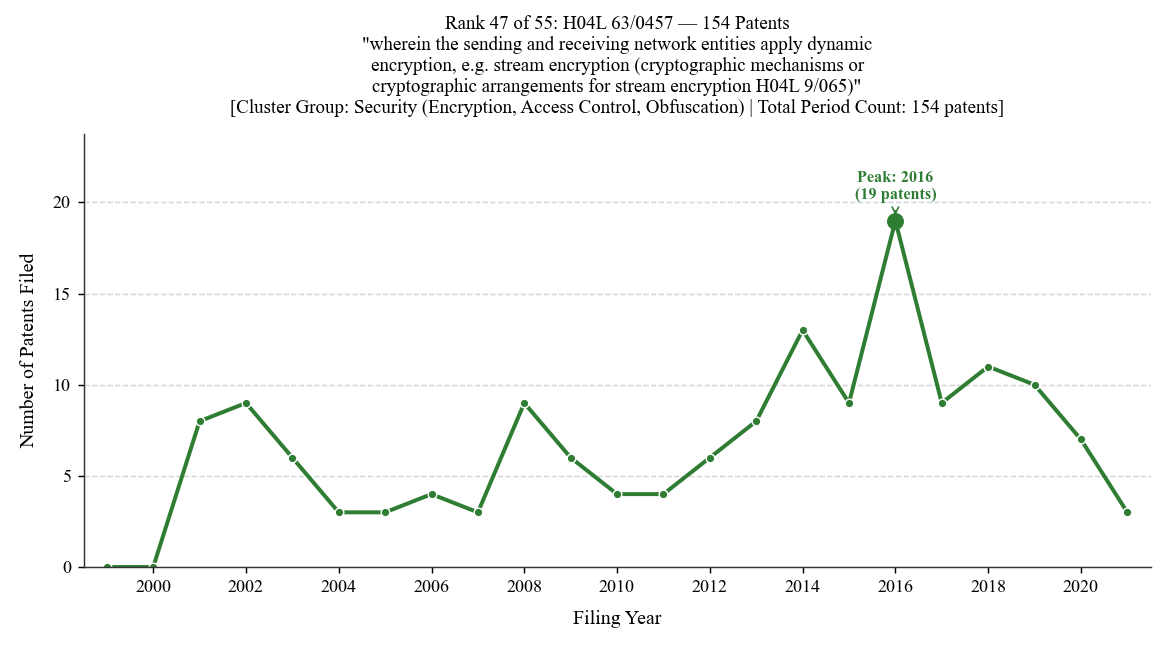

In [112]:
# Rank 47: H04L 63/0457 (154 patents)
# Peak: 2016 (19 patents) | Files: fig_rank_47_H04L63_0457.{png,pdf,svg}


### Rank 48. H04W 12/03: Protecting confidentiality, e.g. by encryption... (142 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Protecting confidentiality, e.g. by encryption"*


Rank 48: H04W 12/03 | Total: 142 patents | Peak: 2021 (59 patents)


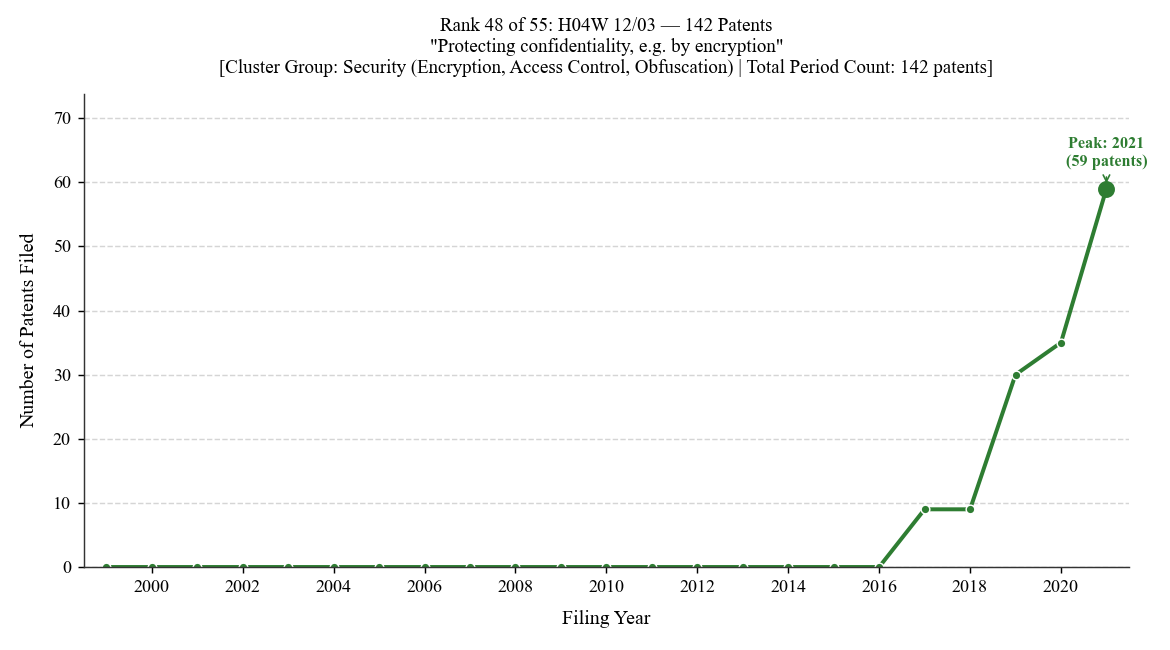

In [114]:
# Rank 48: H04W 12/03 (142 patents)
# Peak: 2021 (59 patents) | Files: fig_rank_48_H04W12_03.{png,pdf,svg}


### Rank 49. H04L 63/0414: during transmission, i.e. party's identity is protected against eavesdropping, e... (136 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"during transmission, i.e. party's identity is protected against eavesdropping, e.g. by using temporary identifiers, but is known to the other party or parties involved in the communication"*


Rank 49: H04L 63/0414 | Total: 136 patents | Peak: 2015 (18 patents)


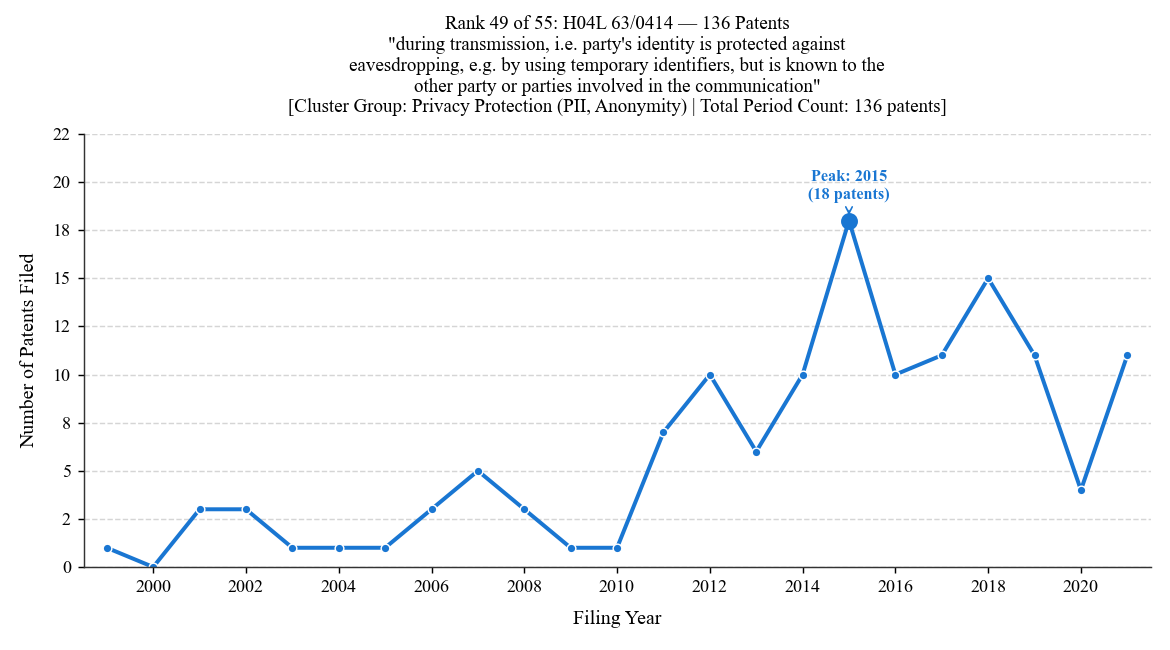

In [116]:
# Rank 49: H04L 63/0414 (136 patents)
# Peak: 2015 (18 patents) | Files: fig_rank_49_H04L63_0414.{png,pdf,svg}


### Rank 50. H04W 12/033: of the user plane, e.g. user's traffic... (135 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"of the user plane, e.g. user's traffic"*


Rank 50: H04W 12/033 | Total: 135 patents | Peak: 2020 (47 patents)


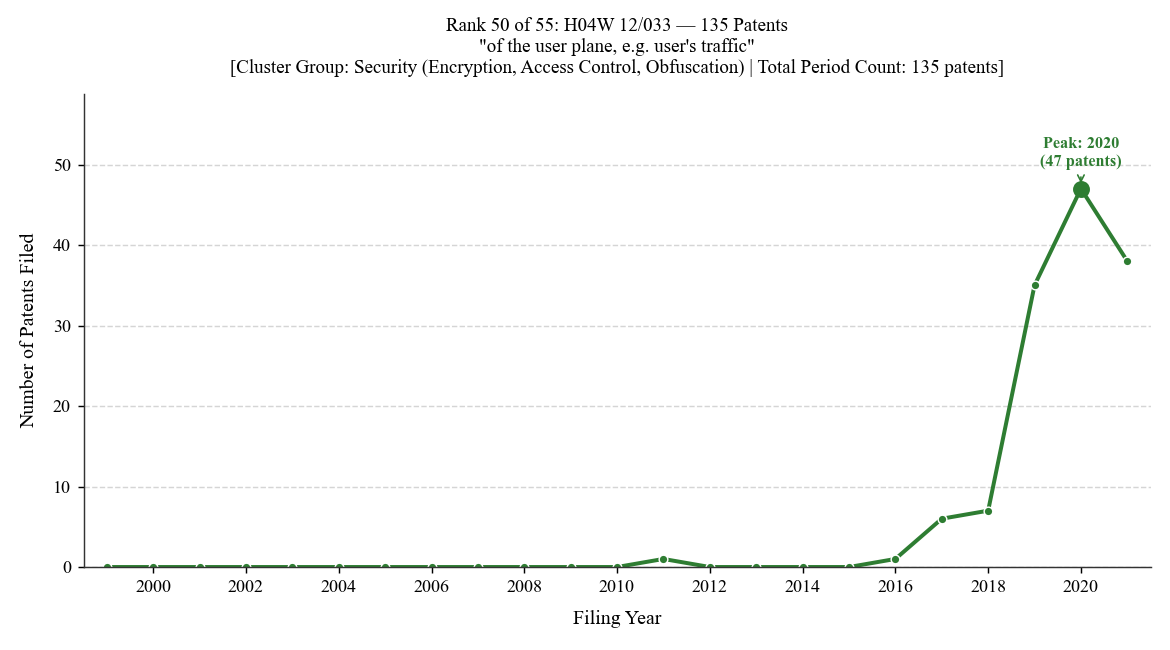

In [118]:
# Rank 50: H04W 12/033 (135 patents)
# Peak: 2020 (47 patents) | Files: fig_rank_50_H04W12_033.{png,pdf,svg}


### Rank 51. G06Q 20/383: Anonymous user system... (131 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"Anonymous user system"*


Rank 51: G06Q 20/383 | Total: 131 patents | Peak: 2019 (16 patents)


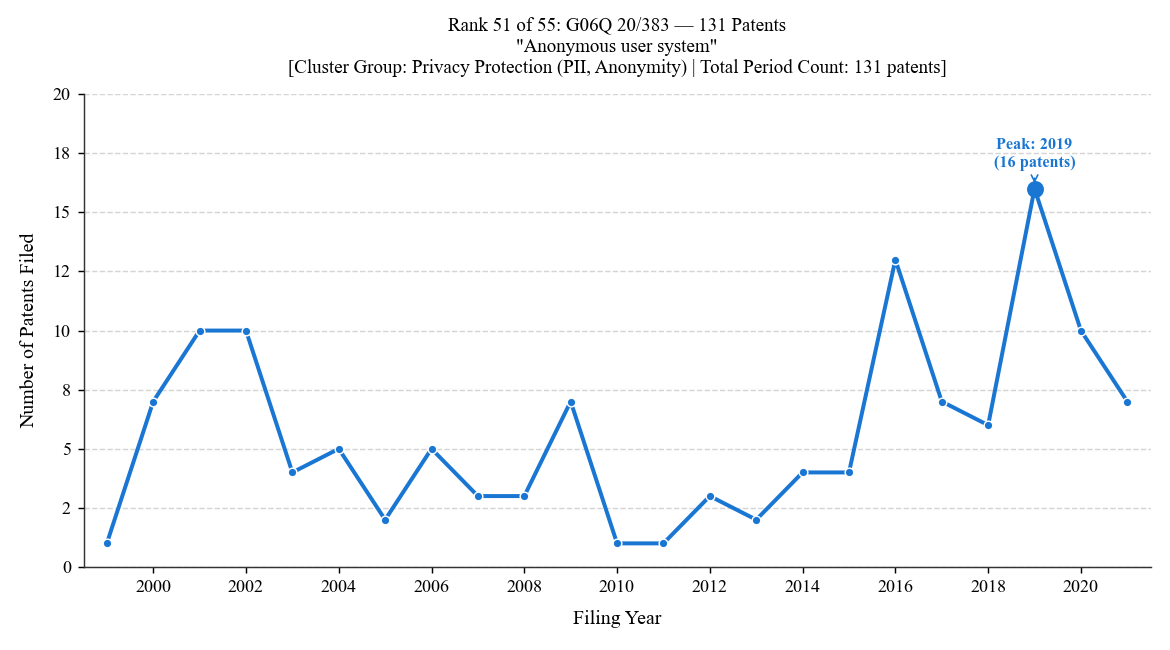

In [120]:
# Rank 51: G06Q 20/383 (131 patents)
# Peak: 2019 (16 patents) | Files: fig_rank_51_G06Q20_383.{png,pdf,svg}


### Rank 52. H04L 63/1475: Passive attacks, e.g. eavesdropping or listening without modification of the tra... (124 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"Passive attacks, e.g. eavesdropping or listening without modification of the traffic monitored"*


Rank 52: H04L 63/1475 | Total: 124 patents | Peak: 2019 (20 patents)


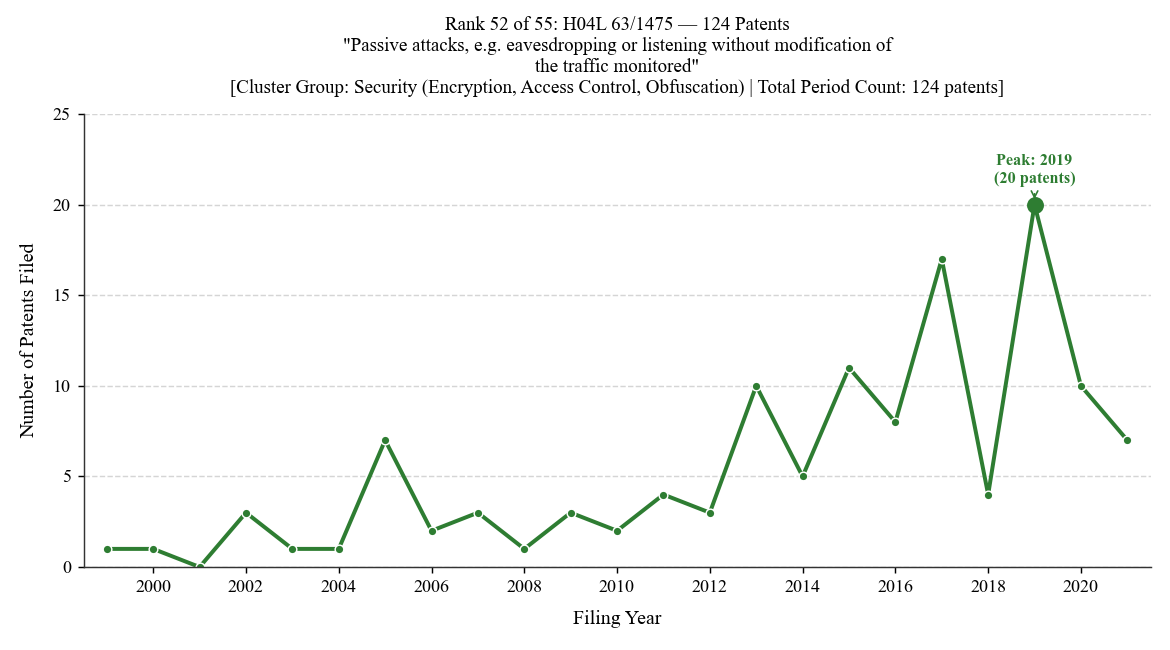

In [122]:
# Rank 52: H04L 63/1475 (124 patents)
# Peak: 2019 (20 patents) | Files: fig_rank_52_H04L63_1475.{png,pdf,svg}


### Rank 53. G06Q 20/3678: e-cash details, e.g. blinded, divisible or detecting double spending... (121 Patents)
- **Group**: Privacy Protection (PII, Anonymity)
- **Full Definition**: *"e-cash details, e.g. blinded, divisible or detecting double spending"*


Rank 53: G06Q 20/3678 | Total: 121 patents | Peak: 2019 (28 patents)


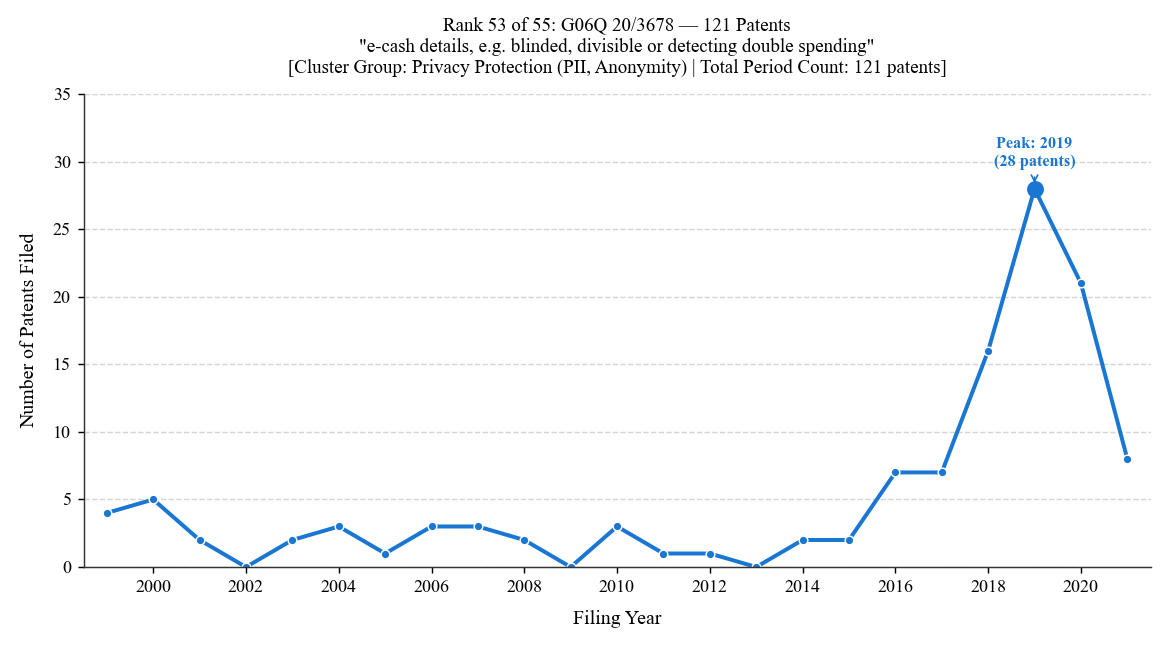

In [124]:
# Rank 53: G06Q 20/3678 (121 patents)
# Peak: 2019 (28 patents) | Files: fig_rank_53_G06Q20_3678.{png,pdf,svg}


### Rank 54. H04L 63/0478: applying multiple layers of encryption, e.g. nested tunnels or encrypting the co... (118 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"applying multiple layers of encryption, e.g. nested tunnels or encrypting the content with a first key and then with at least a second key (cryptographic mechanisms or cryptographic arrangements using a plurality of keys or algorithms H04L 9/14)"*


Rank 54: H04L 63/0478 | Total: 118 patents | Peak: 2018 (18 patents)


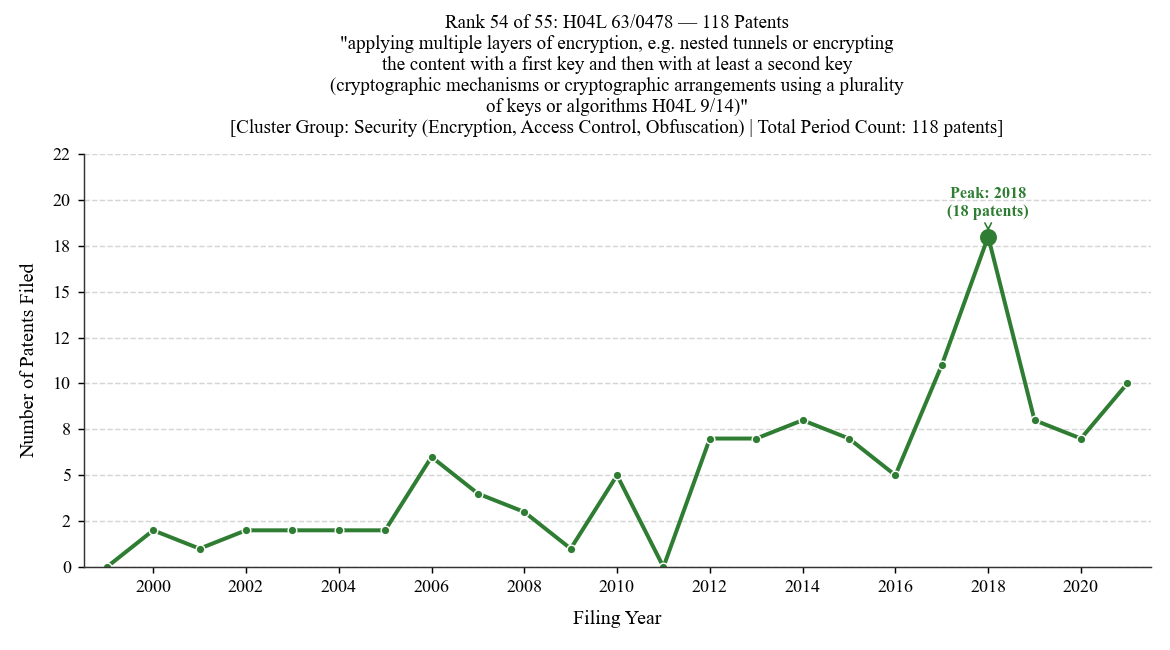

In [126]:
# Rank 54: H04L 63/0478 (118 patents)
# Peak: 2018 (18 patents) | Files: fig_rank_54_H04L63_0478.{png,pdf,svg}


### Rank 55. H04W 12/037: of the control plane, e.g. signalling traffic... (100 Patents)
- **Group**: Security (Encryption, Access Control, Obfuscation)
- **Full Definition**: *"of the control plane, e.g. signalling traffic"*


Rank 55: H04W 12/037 | Total: 100 patents | Peak: 2020 (40 patents)


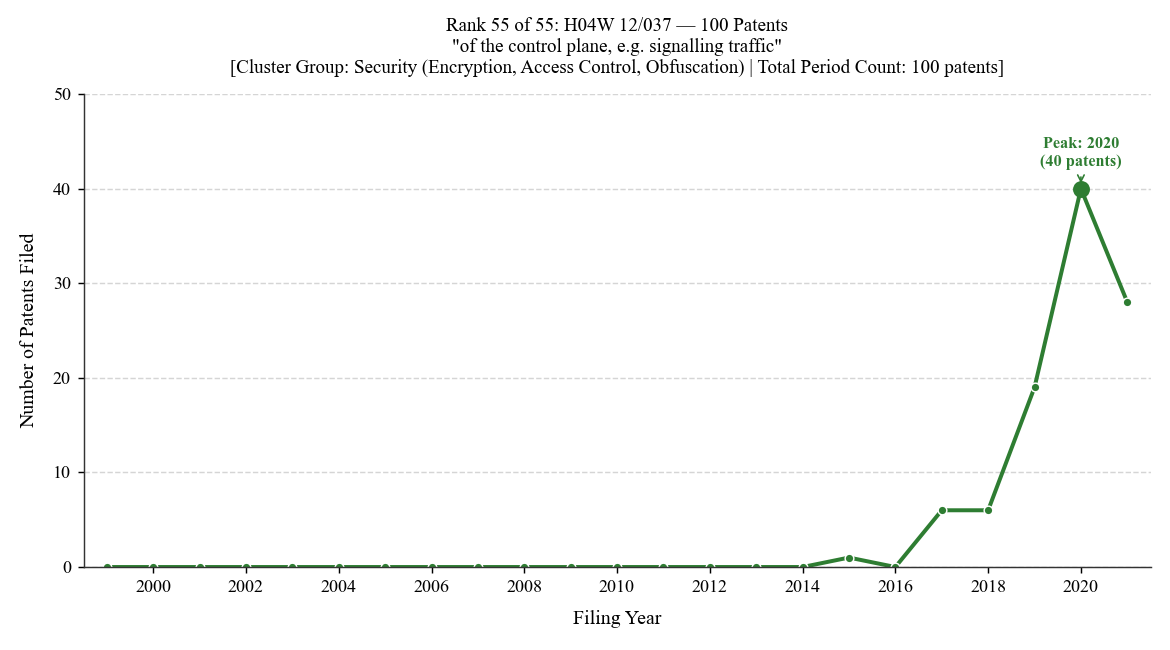

In [128]:
# Rank 55: H04W 12/037 (100 patents)
# Peak: 2020 (40 patents) | Files: fig_rank_55_H04W12_037.{png,pdf,svg}
